In [114]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import scipy.stats as stats

In [115]:
# Load the dataset
raw_df = pd.read_csv("./dataset/WOD_1931-2025.csv")

C:\Users\simra\AppData\Local\Temp\ipykernel_30728\898108334.py:2: DtypeWarning: Columns (19,22,31,32,34,35,38,39) have mixed types. Specify dtype option on import or set low_memory=False.
  raw_df = pd.read_csv("./dataset/WOD_1931-2025.csv")


#### Initial Data Understanding

In [116]:
raw_df.sample(5)

,ID,Source,OrgID,X,Y,Lat,Lon,Day,Month,Year,...,DSRNoon,PrecipNoon,Precip24hr,Precip48hr,Precip72hr,NoRain1,NoRain2,NoRain3,SOI,ENSO
29071,WOD29072,FENZ,F0758218,1232663.00,4879674.00,-46.14,168.24,4,9,2010,...,0.00,3.60,1.20,12.40,12.40,0.00,1.00,5.00,24.90,La Nina
66760,WOD35280,FENZ,F1076265,1784400.00,5837654.00,-37.59,175.09,20,11,2011,...,4.62,-9999.00,-9999.00,-9999.00,-9999.00,-9999.00,-9999.00,-9999.00,13.80,La Nina
47043,WOD98576,FENZ,M659022,1261533.00,4961594.00,-45.42,168.67,18,2,2007,...,1.08,0.00,0.00,-9999.00,-9999.00,9.00,15.00,17.00,-2.70,Neutral
41983,WOD93516,FENZ,M390978,1456904.00,5113064.00,-44.12,171.21,7,12,2003,...,3.96,0.00,0.00,0.00,0.00,4.00,9.00,10.00,9.30,Neutral
47250,WOD98783,FENZ,M666859,1511606.00,5201912.00,-43.33,171.91,19,3,2007,...,15.01,0.00,0.00,0.20,0.20,5.00,6.00,23.00,-1.40,Neutral


In [117]:
raw_df.columns

Index(['ID', 'Source', 'OrgID', 'X', 'Y', 'Lat', 'Lon', 'Day', 'Month', 'Year',
       ...
       'DSRNoon', 'PrecipNoon', 'Precip24hr', 'Precip48hr', 'Precip72hr',
       'NoRain1', 'NoRain2', 'NoRain3', 'SOI', 'ENSO'],
      dtype='object', length=109)

In [118]:
summary = pd.DataFrame({
    "dtype": raw_df.dtypes.astype(str),
    "missing_pct": (raw_df.isna().mean() * 100).round(2),
    "unique_values": raw_df.nunique(dropna=True)
})

print(summary.to_string())

              dtype  missing_pct  unique_values
ID           object         0.00         128020
Source       object         0.00              2
OrgID        object         0.00         123060
X           float64         0.00          99631
Y           float64         0.00         105346
Lat         float64         0.00         116668
Lon         float64         0.00         116668
Day           int64         0.00             31
Month         int64         0.00             12
Year          int64         0.00             78
Time         object         0.00           1441
Hour        float64         0.00             25
Minute      float64         0.00             61
Season       object         0.00              4
StartFY       int64         0.00             75
EndFY         int64         0.00             75
FY           object         0.00             75
AreaHa      float64         0.00           1110
AreaCat      object         0.00              6
OrgVeg       object         0.00        

In [119]:
# Check whether -9999 or other placeholders exist
for col in raw_df.columns:
    count = raw_df[col].isin([-9999, -9999.0]).sum()
    if count:
        print(col, count)

Hour 5482
Minute 5482
OrgVeg 111636
OrgIDDrop 111636
Elev 986
MinElev 125998
MaxElev 125998
Slope 910
MinSlope 125994
MaxSlope 125994
AspectDeg 4049
AspectCar2 98304
AspectCar3 98304
LandCvr2 98304
LandCvr3 98304
Landform2 98304
Landform3 98304
WxID 6601
WxDist 6601
Temp 37340
TempNoon 6601
TempMax8B 41640
TempMin8B 41640
TempAvg8B 41640
TempMax8A 41288
TempMin8A 41288
TempAvg8A 41288
RH 37375
RHNoon 6602
RHMax8B 41771
RHMin8B 41771
RHAvg8B 41771
RHMax8A 41377
RHMin8A 41377
RHAvg8A 41377
WS 37304
WSNoon 6603
WSMax8B 43123
WSMin8B 43123
WSAvg8B 43123
WSMax8A 42793
WSMin8A 42793
WSAvg8A 42793
WD 38182
SoilMoist 119354
SoilTemp 119337
FFMCNoon 6601
FFMC 88279
FFMC8B 88345
FFMC8A 88275
ISINoon 6601
ISI 88279
ISI8B 88345
ISI8A 88276
FWINoon 6601
FWI 88279
FWI8B 88345
FWI8A 88276
FDCNoon 57158
FDC 101879
FDC8B 101921
FDC8A 101874
HFINoon 57161
HFI 101879
HFI8B 101921
HFI8A 101874
ROSNoon 57161
ROS 101879
ROS8B 101921
ROS8A 101874
DMCNoon 13081
DCNoon 13080
BUINoon 13080
DSRNoon 6601
PrecipNo

In [120]:
# Useful Features
features = [
    # Weather at detection
    "Temp", "RH", "WS", "WD",
    # Fire-weather indices
    "FFMC", "ISI", "FWI",
    # Recent rainfall and drying
    "Precip24hr", "NoRain1", "NoRain2", "NoRain3",
    # Fuel and land cover
    "FuelType", "FuelClass", "LandCvr",
    # Topography
    "Elev", "Slope", "AspectDeg", "Landform",
    # Location and time
    "Lat", "Lon", "FENZDist",
    "Day", "Month", "Hour", "Year",
    # Climate
    "SOI", "ENSO"
]

target = "AreaHa"

In [121]:
# Extract only required columns
df = raw_df[features + [target]]

In [122]:
df.sample(5)

,Temp,RH,WS,WD,FFMC,ISI,FWI,Precip24hr,NoRain1,NoRain2,...,Lat,Lon,FENZDist,Day,Month,Hour,Year,SOI,ENSO,AreaHa
121423,22.20,67.00,3.09,211.00,-9999.00,-9999.00,-9999.00,-9999.00,59.00,60.00,...,-37.69,176.15,Bay of Plenty,29,12,10.00,2024,10.80,Neutral,0.00
110373,21.00,34.00,6.00,3.00,93.28,20.25,42.82,0.00,13.00,14.00,...,-45.11,169.62,Otago,23,2,22.00,2021,11.50,La Nina,0.00
44365,9.40,72.00,2.90,182.00,-9999.00,-9999.00,-9999.00,0.00,1.00,2.00,...,-43.57,172.61,Canterbury,11,7,16.00,2005,0.90,Neutral,0.00
66468,-9999.00,-9999.00,-9999.00,-9999.00,-9999.00,-9999.00,-9999.00,-9999.00,23.00,26.00,...,-35.76,174.48,Northland,17,10,12.00,2011,7.30,La Nina,0.00
90186,22.50,38.00,5.40,268.00,88.21,8.84,13.27,0.20,3.00,8.00,...,-39.93,176.88,Hawkes Bay,16,11,16.00,2016,-0.70,Neutral,1.00


In [123]:
pd.set_option("display.float_format", "{:.2f}".format)
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 128020 entries, 0 to 128019
Data columns (total 28 columns):
 #   Column      Non-Null Count   Dtype  
---  ------      --------------   -----  
 0   Temp        128020 non-null  float64
 1   RH          128020 non-null  float64
 2   WS          128020 non-null  float64
 3   WD          128020 non-null  float64
 4   FFMC        128020 non-null  float64
 5   ISI         128020 non-null  float64
 6   FWI         128020 non-null  float64
 7   Precip24hr  128020 non-null  float64
 8   NoRain1     128020 non-null  float64
 9   NoRain2     128020 non-null  float64
 10  NoRain3     128020 non-null  float64
 11  FuelType    128020 non-null  object 
 12  FuelClass   128020 non-null  object 
 13  LandCvr     128020 non-null  object 
 14  Elev        128020 non-null  float64
 15  Slope       128020 non-null  float64
 16  AspectDeg   128020 non-null  float64
 17  Landform    128020 non-null  object 
 18  Lat         128020 non-null  float64
 19  Lo

In [124]:
df.duplicated().sum()

np.int64(22)

In [125]:
df.replace(-9999, np.nan, inplace=True)

C:\Users\simra\AppData\Local\Temp\ipykernel_30728\2173504647.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df.replace(-9999, np.nan, inplace=True)


#### Exploratory Data Analysis

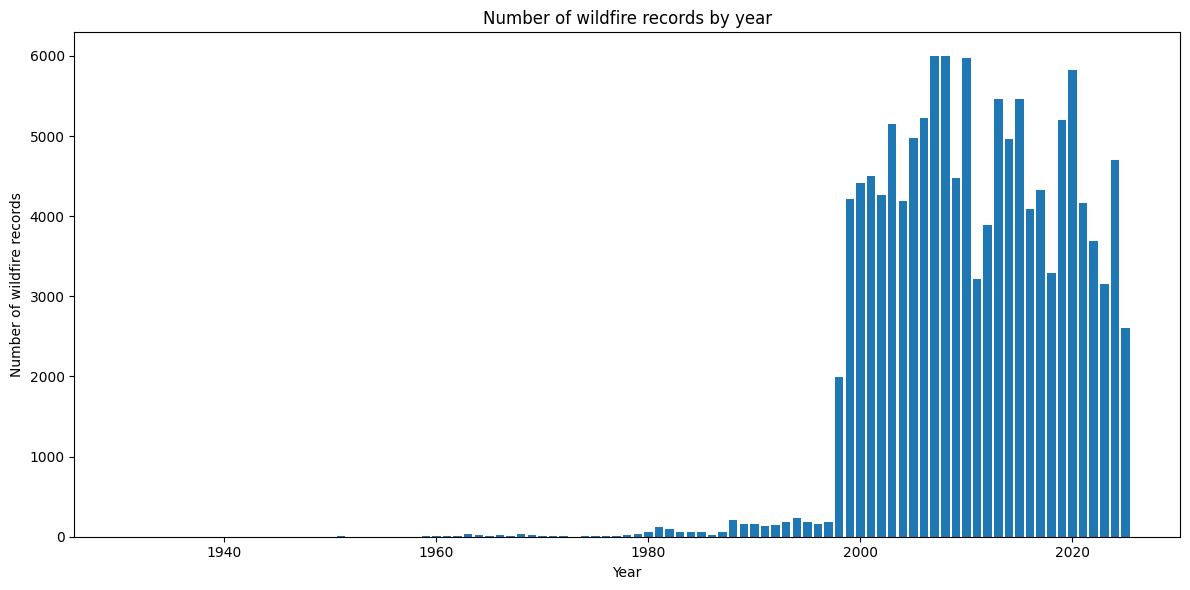

In [13]:
year_counts = df["Year"].value_counts().sort_index()

# Plot
plt.figure(figsize=(12, 6))
plt.bar(year_counts.index, year_counts.values)

plt.xlabel("Year")
plt.ylabel("Number of wildfire records")
plt.title("Number of wildfire records by year")

plt.tight_layout()
plt.show()

<BarContainer object of 28 artists>

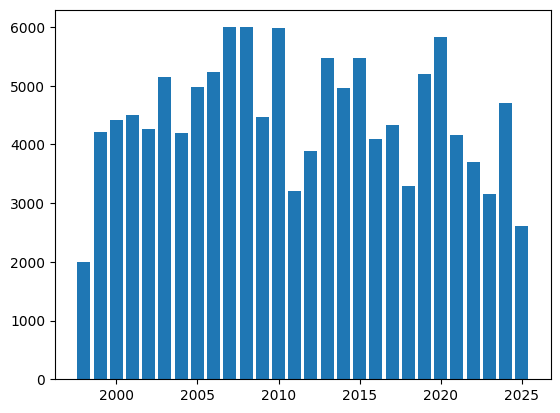

In [14]:
year_counts = df[(df["Year"]>=1998)]["Year"].value_counts().sort_index()
plt.bar(year_counts.index, year_counts.values)

In [15]:
df = df[df["Year"] >= 1998]

In [16]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 125407 entries, 0 to 128019
Data columns (total 28 columns):
 #   Column      Non-Null Count   Dtype  
---  ------      --------------   -----  
 0   Temp        90544 non-null   float64
 1   RH          90510 non-null   float64
 2   WS          90580 non-null   float64
 3   WD          89707 non-null   float64
 4   FFMC        39741 non-null   float64
 5   ISI         39741 non-null   float64
 6   FWI         39741 non-null   float64
 7   Precip24hr  85638 non-null   float64
 8   NoRain1     94104 non-null   float64
 9   NoRain2     93799 non-null   float64
 10  NoRain3     93526 non-null   float64
 11  FuelType    125407 non-null  object 
 12  FuelClass   125407 non-null  object 
 13  LandCvr     125407 non-null  object 
 14  Elev        124555 non-null  float64
 15  Slope       124628 non-null  float64
 16  AspectDeg   121536 non-null  float64
 17  Landform    125407 non-null  object 
 18  Lat         125407 non-null  float64
 19  Lon    

In [17]:
df.describe()

,Temp,RH,WS,WD,FFMC,ISI,FWI,Precip24hr,NoRain1,NoRain2,...,Slope,AspectDeg,Lat,Lon,Day,Month,Hour,Year,SOI,AreaHa
count,90544.00,90510.00,90580.00,89707.00,39741.00,39741.00,39741.00,85638.00,94104.00,93799.00,...,124628.00,121536.00,125407.00,125407.00,125407.00,125407.00,122538.00,125407.00,125364.00,125407.00
mean,16.99,65.91,3.96,185.30,77.19,4.02,7.55,0.85,12.48,16.21,...,2.49,175.01,-40.05,173.95,15.31,6.28,14.37,2011.33,2.08,1.16
std,5.51,17.99,2.96,108.32,14.94,5.46,9.11,3.89,19.42,19.51,...,4.16,92.71,3.20,4.61,8.95,4.03,5.22,7.62,10.06,39.59
min,-32.90,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,...,0.00,0.00,-47.21,-176.61,1.00,1.00,0.00,1998.00,-28.60,-0.00
25%,13.50,54.00,1.90,80.00,77.23,1.47,1.28,0.00,2.00,4.00,...,0.00,99.06,-43.35,172.66,7.00,2.00,12.00,2005.00,-5.50,0.00
50%,17.20,66.00,3.30,209.00,81.98,2.59,4.72,0.00,4.00,8.00,...,1.00,164.95,-39.59,174.70,15.00,5.00,15.00,2011.00,1.30,0.00
75%,20.90,79.00,5.14,274.00,84.68,4.43,10.22,0.20,10.00,17.00,...,3.00,255.45,-37.08,175.31,23.00,11.00,18.00,2018.00,9.40,0.00
max,48.00,100.00,38.52,360.00,101.00,122.32,102.85,194.40,90.00,90.00,...,43.00,359.74,-34.16,178.97,31.00,12.00,23.00,2025.00,27.10,6159.00


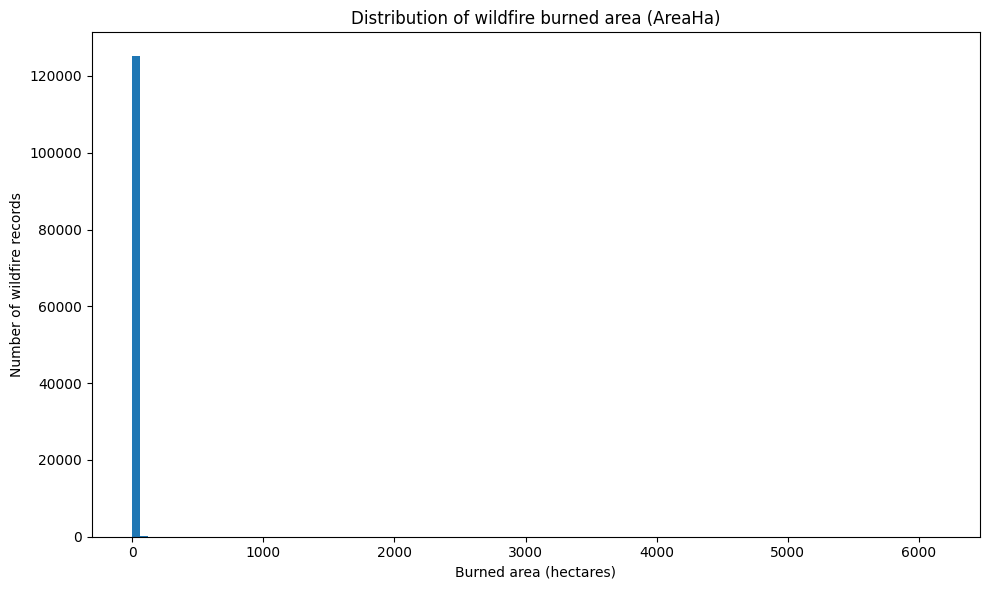

In [18]:
plt.figure(figsize=(10, 6))

plt.hist(df["AreaHa"].dropna(), bins=100)

plt.xlabel("Burned area (hectares)")
plt.ylabel("Number of wildfire records")
plt.title("Distribution of wildfire burned area (AreaHa)")

plt.tight_layout()
plt.show()

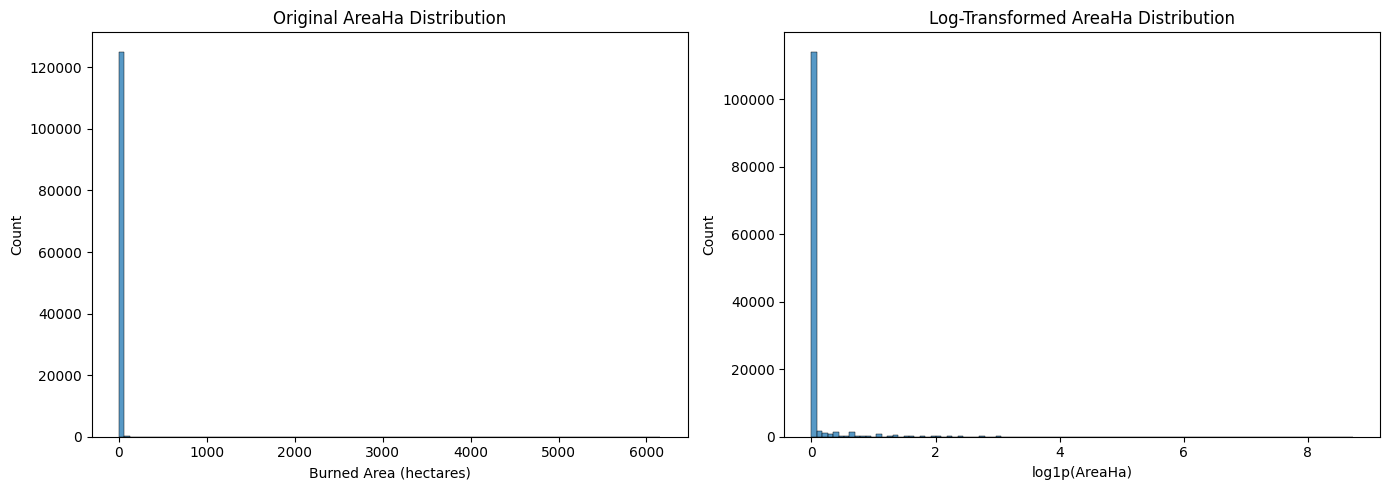

In [19]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Log-transform for visualisation only
log_area = np.log1p(df["AreaHa"])

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.histplot(df["AreaHa"], bins=100, ax=axes[0])
axes[0].set_title("Original AreaHa Distribution")
axes[0].set_xlabel("Burned Area (hectares)")

sns.histplot(log_area, bins=100, ax=axes[1])
axes[1].set_title("Log-Transformed AreaHa Distribution")
axes[1].set_xlabel("log1p(AreaHa)")

plt.tight_layout()
plt.show()

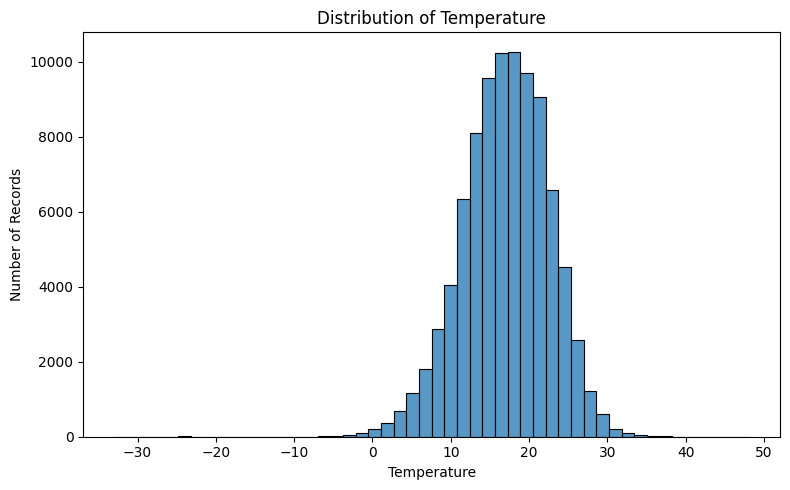

In [20]:
plt.figure(figsize=(8, 5))

sns.histplot(data=df, x="Temp", bins=50)

plt.title("Distribution of Temperature")
plt.xlabel("Temperature")
plt.ylabel("Number of Records")
plt.tight_layout()
plt.show()

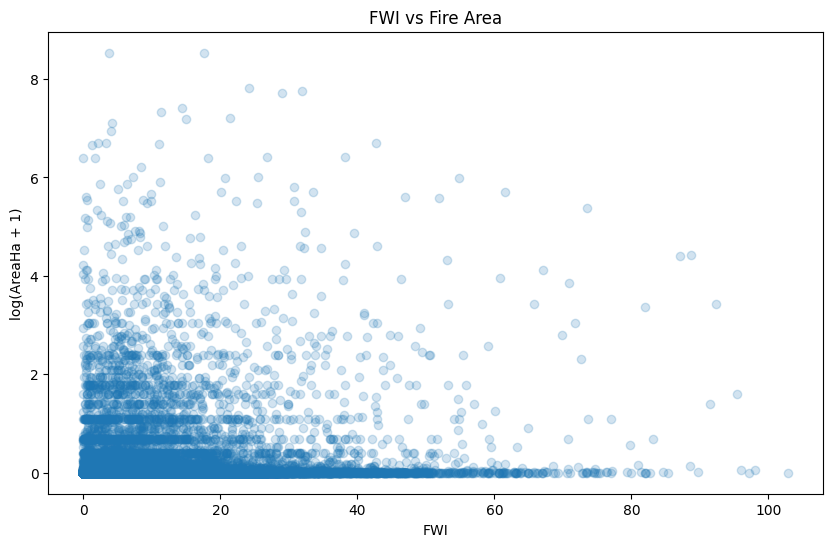

In [21]:
plt.figure(figsize=(10, 6))

plt.scatter(
    df["FWI"],
    np.log1p(df["AreaHa"]),
    alpha=0.2
)

plt.xlabel("FWI")
plt.ylabel("log(AreaHa + 1)")
plt.title("FWI vs Fire Area")

plt.show()

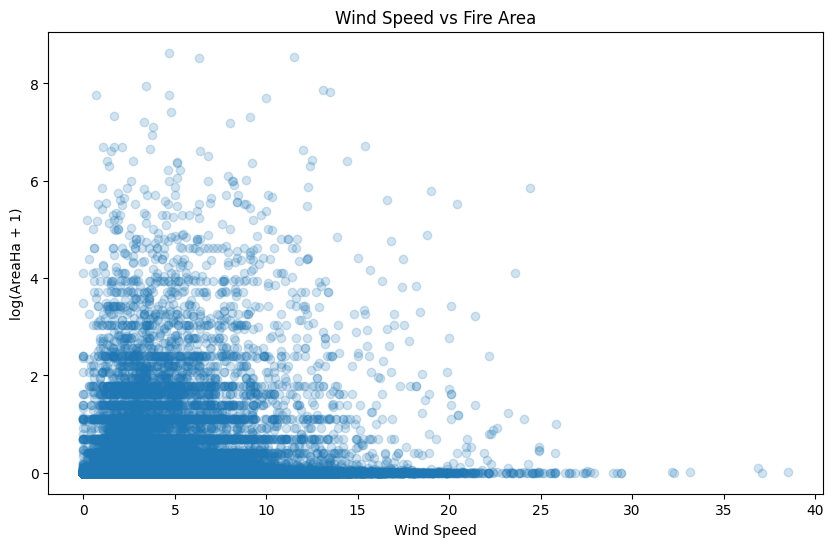

In [22]:
plt.figure(figsize=(10, 6))

plt.scatter(
    df["WS"],
    np.log1p(df["AreaHa"]),
    alpha=0.2
)

plt.xlabel("Wind Speed")
plt.ylabel("log(AreaHa + 1)")
plt.title("Wind Speed vs Fire Area")
plt.show()

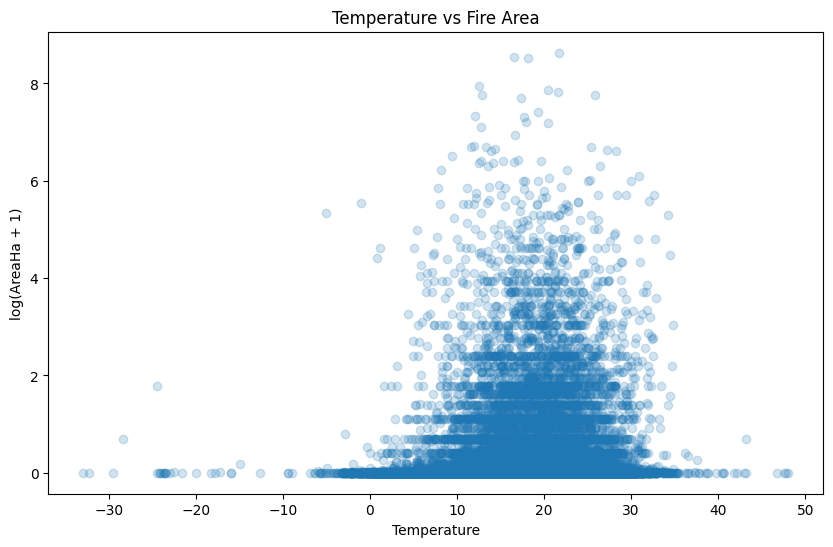

In [23]:
plt.figure(figsize=(10, 6))

plt.scatter(
    df["Temp"],
    np.log1p(df["AreaHa"]),
    alpha=0.2
)

plt.xlabel("Temperature")
plt.ylabel("log(AreaHa + 1)")
plt.title("Temperature vs Fire Area")
plt.show()

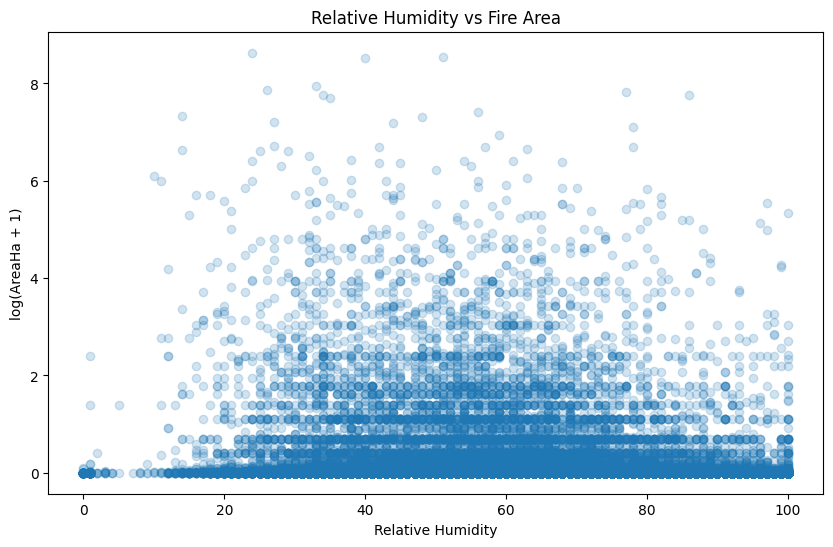

In [24]:
plt.figure(figsize=(10, 6))

plt.scatter(
    df["RH"],
    np.log1p(df["AreaHa"]),
    alpha=0.2
)

plt.xlabel("Relative Humidity")
plt.ylabel("log(AreaHa + 1)")
plt.title("Relative Humidity vs Fire Area")
plt.show()

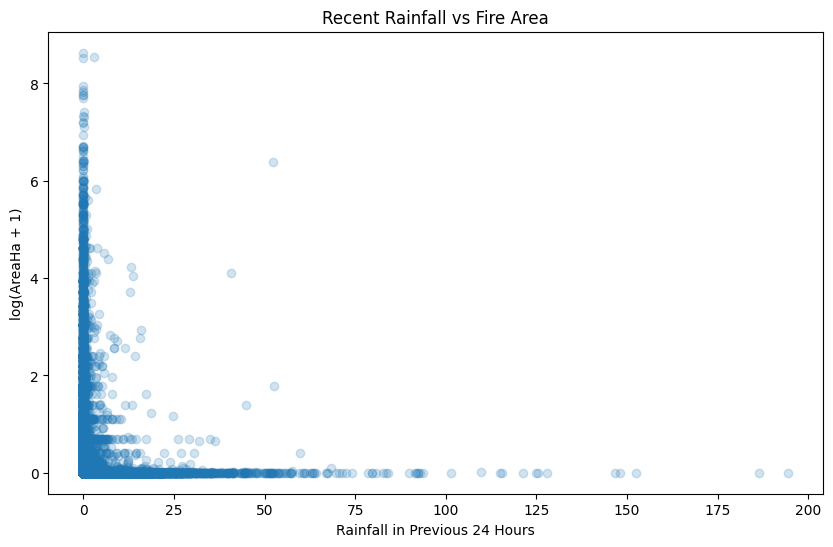

In [25]:
plt.figure(figsize=(10, 6))

plt.scatter(
    df["Precip24hr"],
    np.log1p(df["AreaHa"]),
    alpha=0.2
)

plt.xlabel("Rainfall in Previous 24 Hours")
plt.ylabel("log(AreaHa + 1)")
plt.title("Recent Rainfall vs Fire Area")
plt.show()

In [26]:
# df[["Precip24hr", "AreaHa"]].skew()


log_df = np.log1p(df[["Precip24hr", "AreaHa"]])

log_df.skew()

Precip24hr   3.03
AreaHa       7.64
dtype: float64

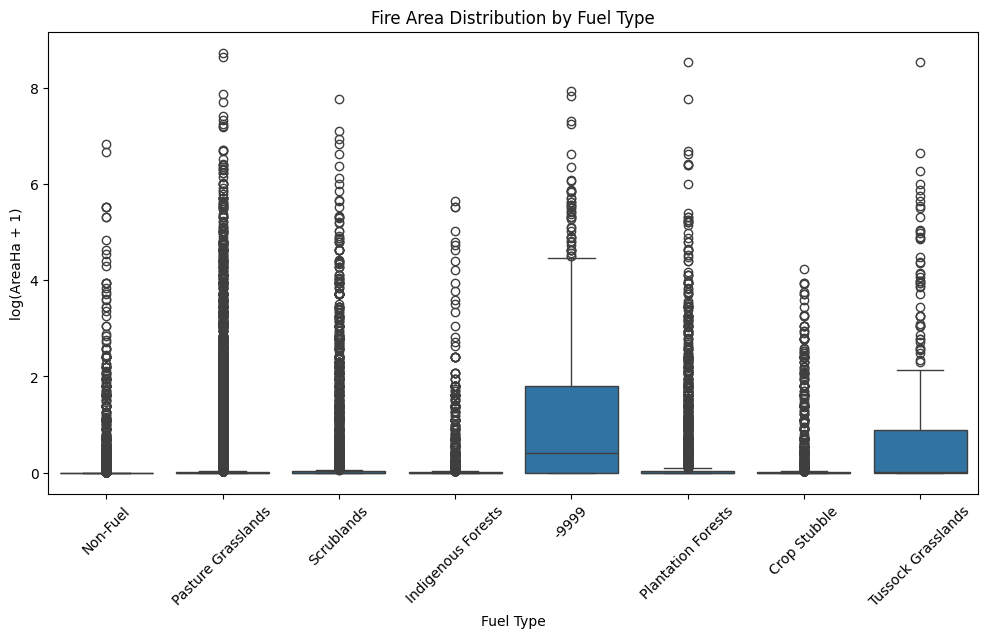

In [27]:
plt.figure(figsize=(12, 6))

sns.boxplot(
    data=df,
    x="FuelType",
    y=np.log1p(df["AreaHa"])
)

plt.xlabel("Fuel Type")
plt.ylabel("log(AreaHa + 1)")
plt.title("Fire Area Distribution by Fuel Type")
plt.xticks(rotation=45)
plt.show()

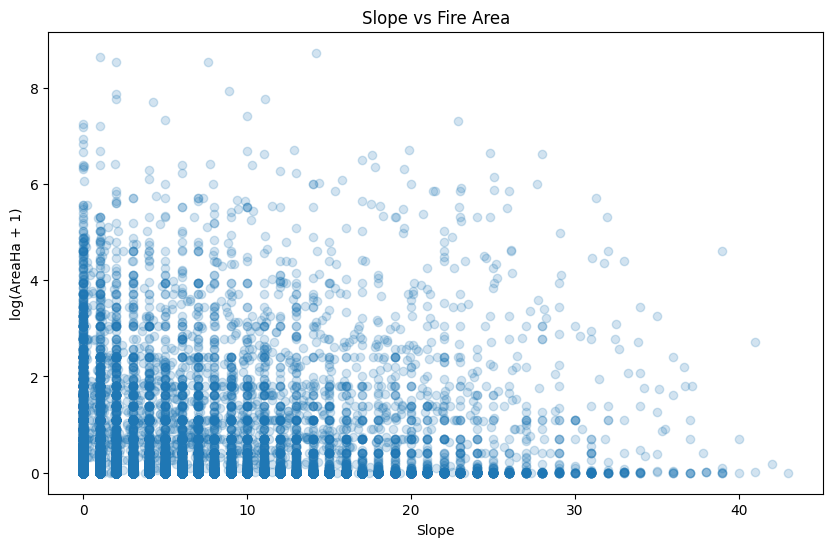

In [28]:
plt.figure(figsize=(10, 6))

plt.scatter(
    df["Slope"],
    np.log1p(df["AreaHa"]),
    alpha=0.2
)

plt.xlabel("Slope")
plt.ylabel("log(AreaHa + 1)")
plt.title("Slope vs Fire Area")
plt.show()

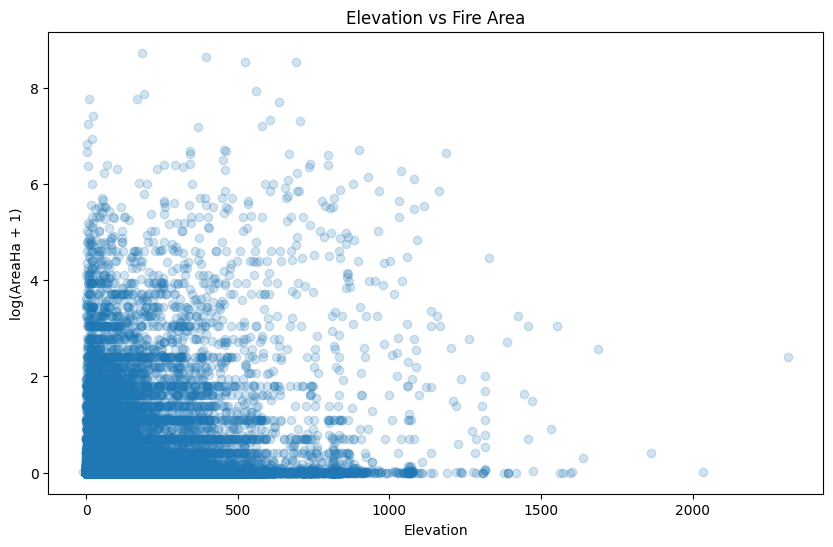

In [29]:
plt.figure(figsize=(10, 6))

plt.scatter(
    df["Elev"],
    np.log1p(df["AreaHa"]),
    alpha=0.2
)

plt.xlabel("Elevation")
plt.ylabel("log(AreaHa + 1)")
plt.title("Elevation vs Fire Area")
plt.show()

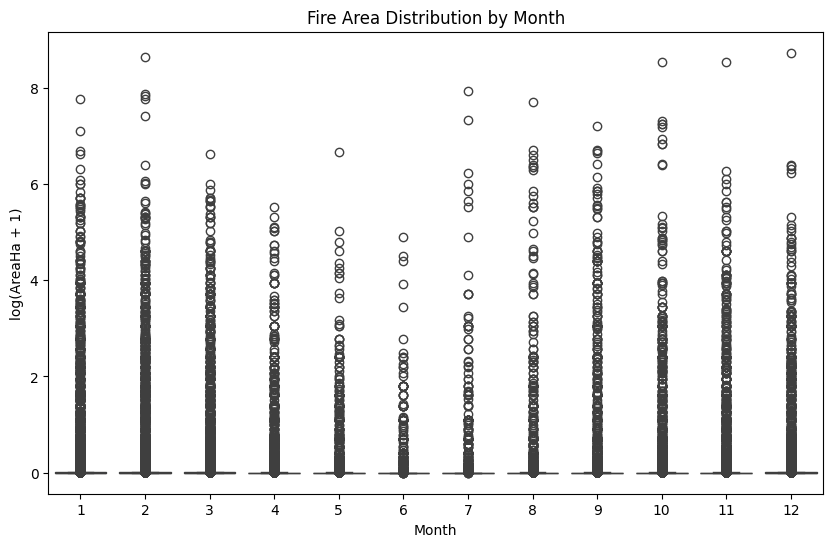

In [30]:
plt.figure(figsize=(10, 6))

sns.boxplot(
    data=df,
    x="Month",
    y=np.log1p(df["AreaHa"])
)

plt.xlabel("Month")
plt.ylabel("log(AreaHa + 1)")
plt.title("Fire Area Distribution by Month")
plt.show()

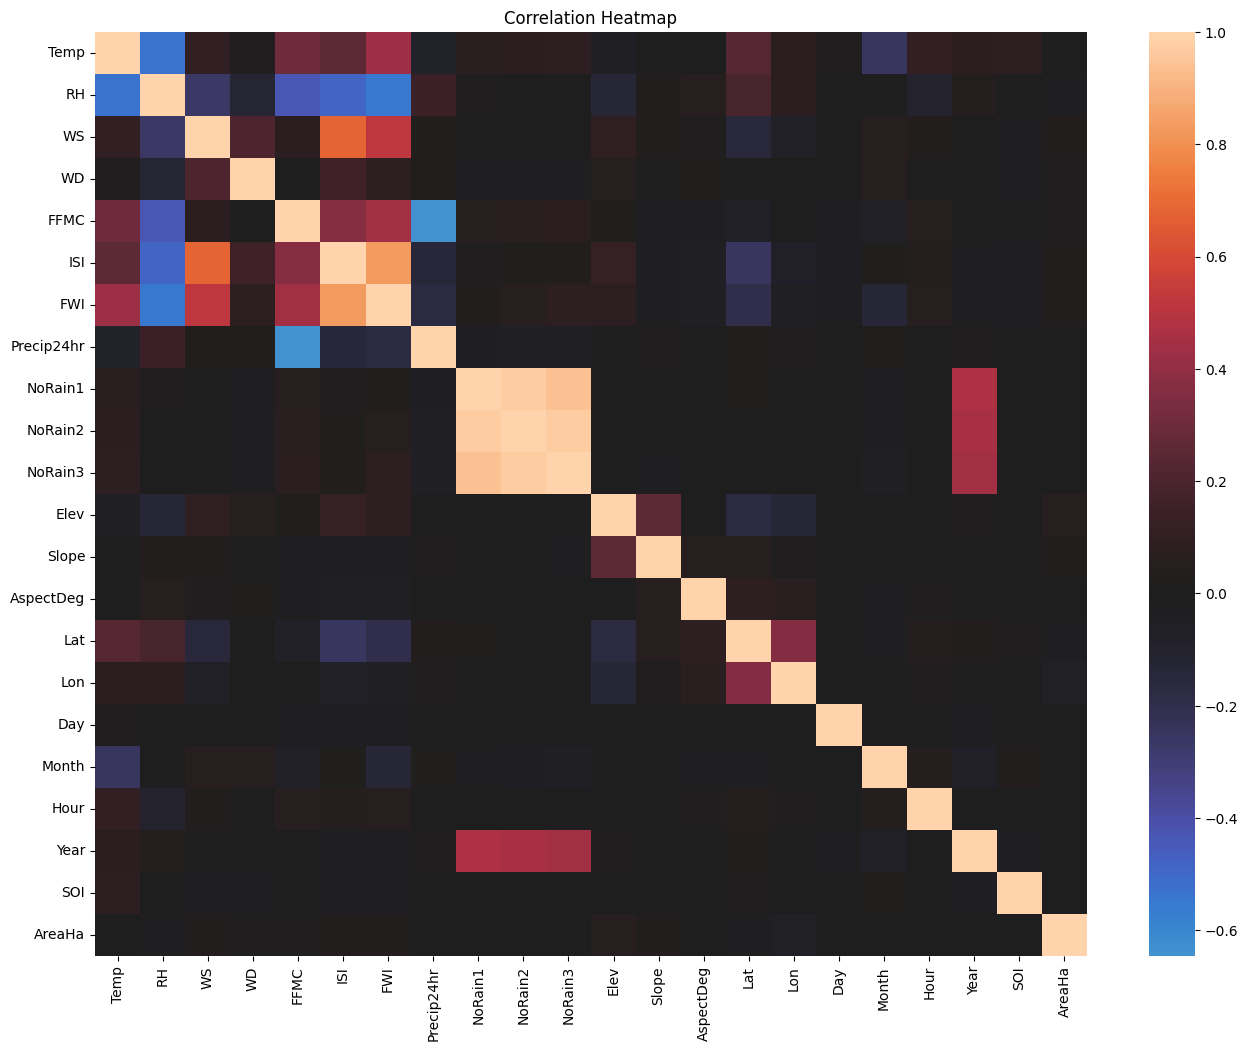

In [31]:
numeric_cols = df.select_dtypes(include="number").columns

plt.figure(figsize=(16, 12))

sns.heatmap(
    df[numeric_cols].corr(),
    center=0
)

plt.title("Correlation Heatmap")
plt.show()

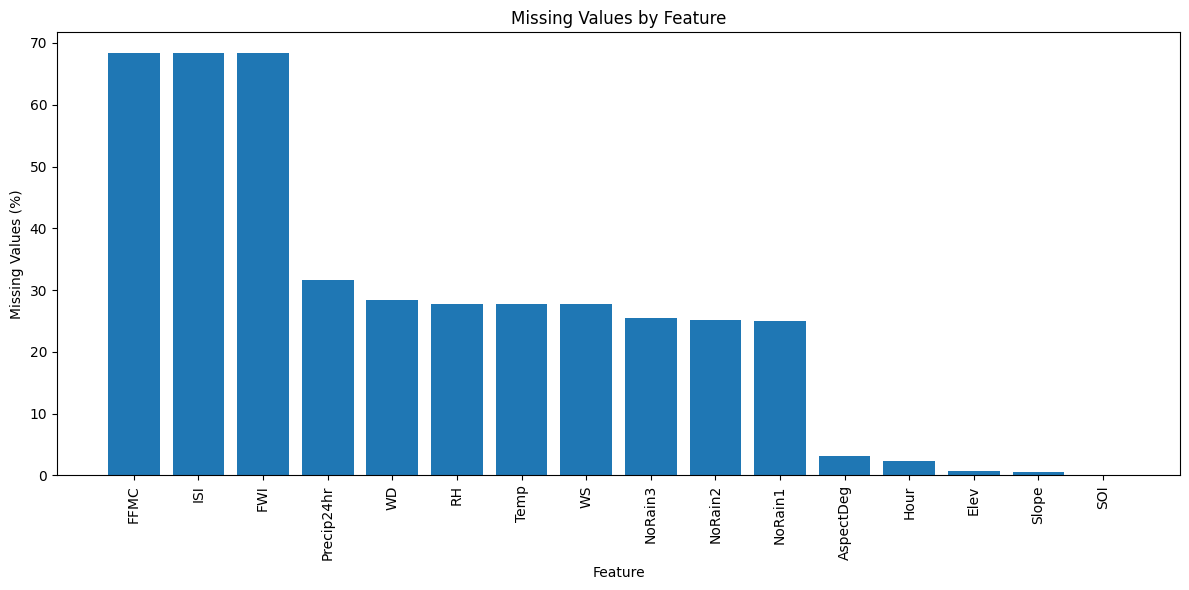

In [32]:
missing = df.isnull().mean() * 100
missing = missing[missing > 0].sort_values(ascending=False)

plt.figure(figsize=(12,6))
plt.bar(missing.index, missing.values)

plt.xlabel("Feature")
plt.ylabel("Missing Values (%)")
plt.title("Missing Values by Feature")
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()

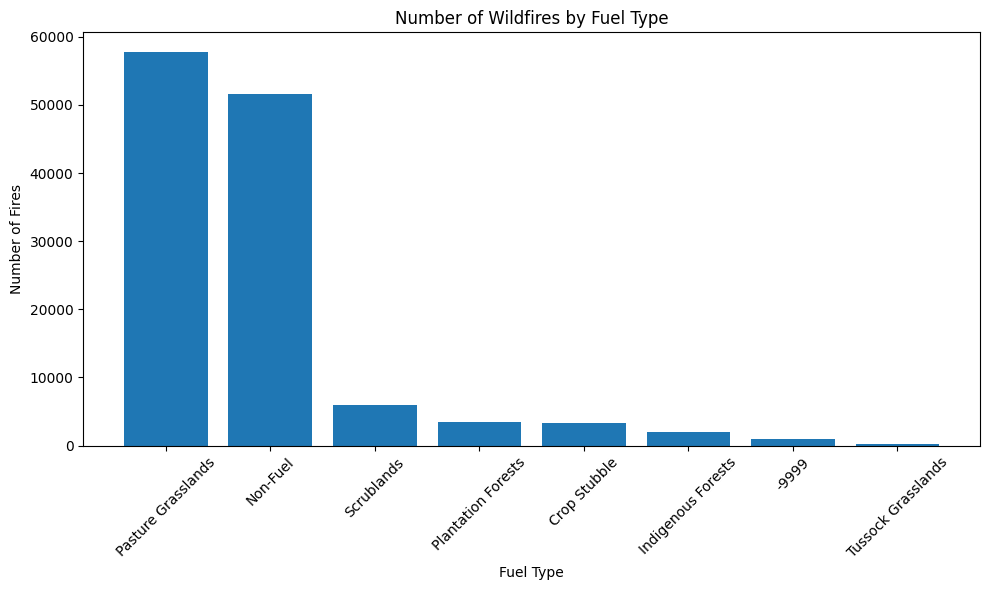

In [33]:
fuel_counts = df["FuelType"].value_counts()

plt.figure(figsize=(10,6))
plt.bar(fuel_counts.index, fuel_counts.values)

plt.xlabel("Fuel Type")
plt.ylabel("Number of Fires")
plt.title("Number of Wildfires by Fuel Type")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

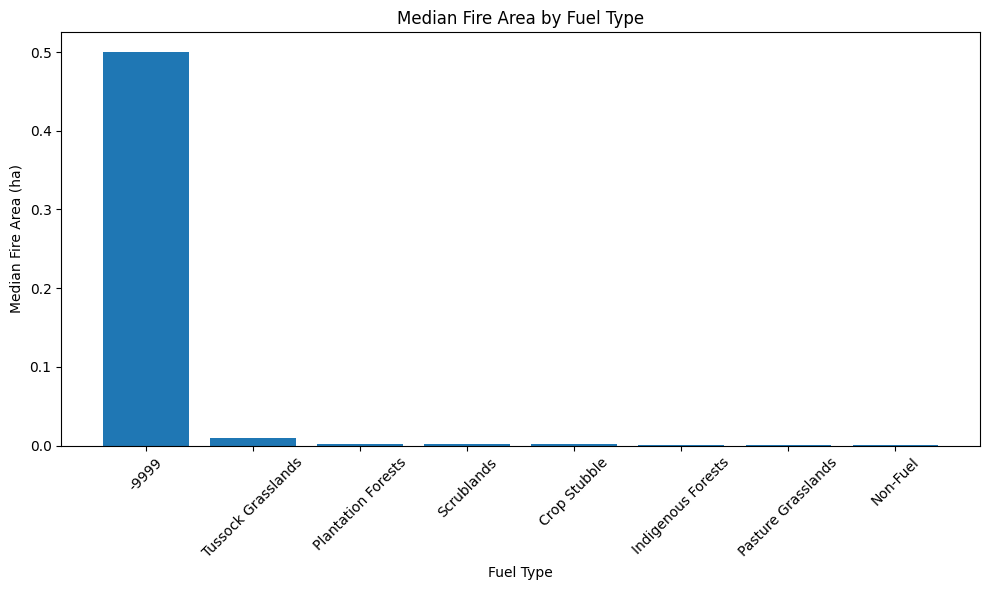

In [34]:
fuel_median = (
    df.groupby("FuelType")["AreaHa"]
    .median()
    .sort_values(ascending=False)
)

plt.figure(figsize=(10,6))
plt.bar(fuel_median.index, fuel_median.values)

plt.xlabel("Fuel Type")
plt.ylabel("Median Fire Area (ha)")
plt.title("Median Fire Area by Fuel Type")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

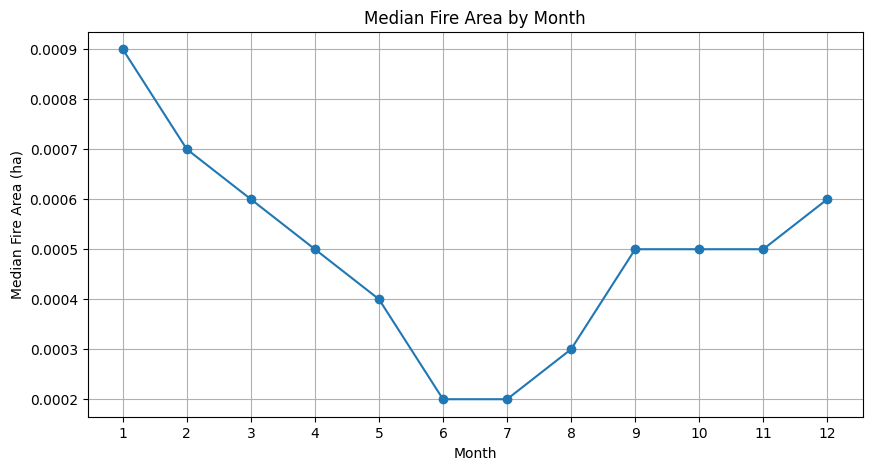

In [35]:
monthly_median = (
    df.groupby("Month")["AreaHa"]
    .median()
)

plt.figure(figsize=(10,5))
plt.plot(
    monthly_median.index,
    monthly_median.values,
    marker="o"
)

plt.xlabel("Month")
plt.ylabel("Median Fire Area (ha)")
plt.title("Median Fire Area by Month")
plt.xticks(range(1,13))
plt.grid(True)
plt.show()

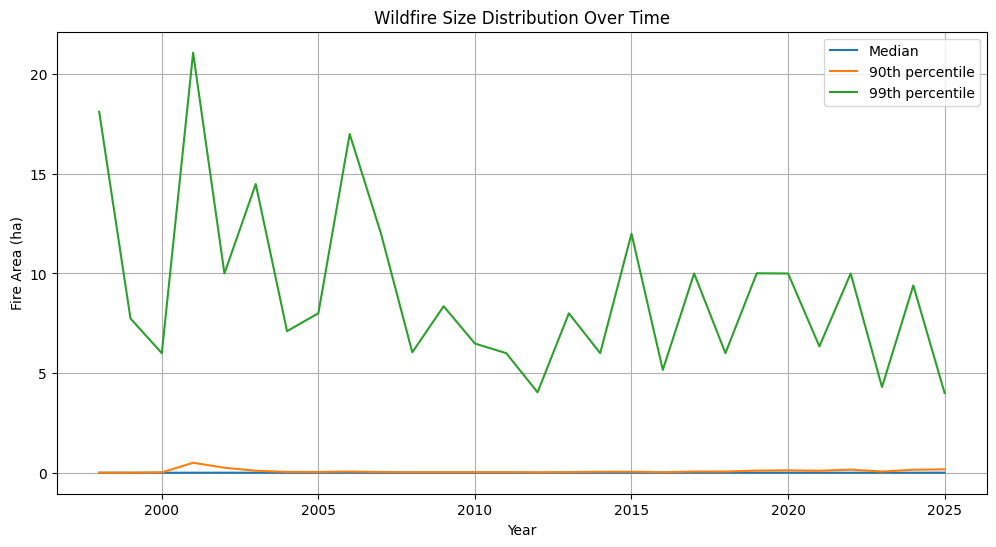

In [36]:
year_area = df.groupby("Year")["AreaHa"].agg(
    median="median",
    p90=lambda x: x.quantile(0.90),
    p99=lambda x: x.quantile(0.99)
)

plt.figure(figsize=(12,6))

plt.plot(year_area.index, year_area["median"], label="Median")
plt.plot(year_area.index, year_area["p90"], label="90th percentile")
plt.plot(year_area.index, year_area["p99"], label="99th percentile")

plt.xlabel("Year")
plt.ylabel("Fire Area (ha)")
plt.title("Wildfire Size Distribution Over Time")
plt.legend()
plt.grid(True)
plt.show()

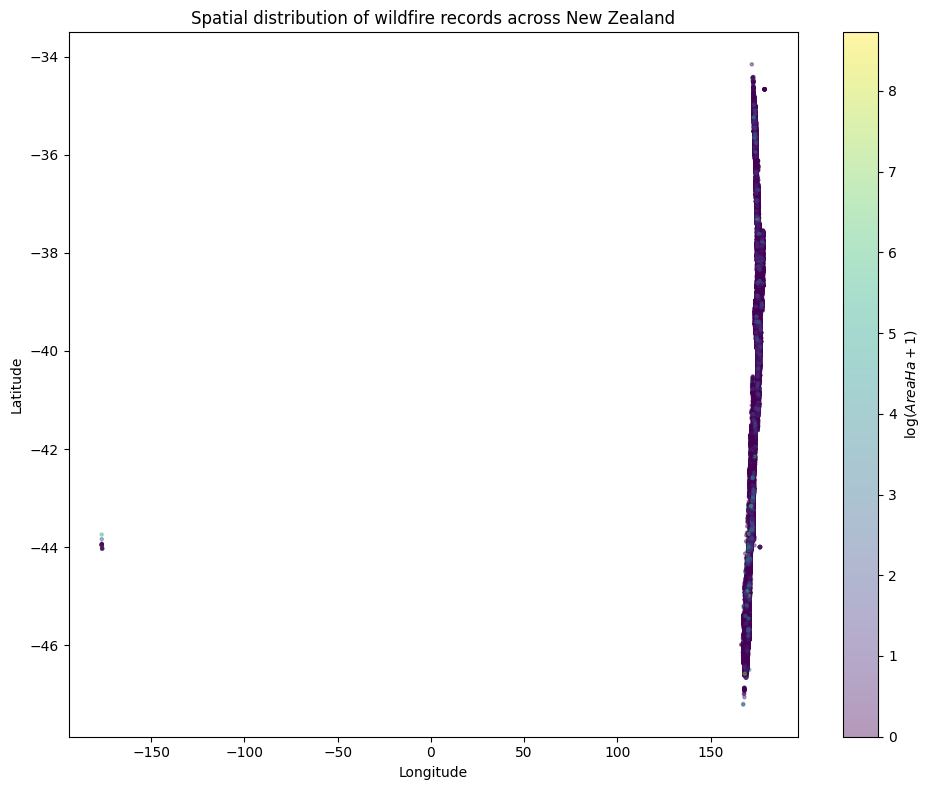

In [37]:
spatial_df = df[
    df["Lon"].notna() &
    df["Lat"].notna() &
    df["AreaHa"].notna()
].copy()

# Log-transform burned area for visualisation
spatial_df["LogArea"] = np.log1p(spatial_df["AreaHa"])

plt.figure(figsize=(10, 8))

scatter = plt.scatter(
    spatial_df["Lon"],
    spatial_df["Lat"],
    c=spatial_df["LogArea"],
    s=5,
    alpha=0.4
)

plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.title("Spatial distribution of wildfire records across New Zealand")

cbar = plt.colorbar(scatter)
cbar.set_label(r"$\log(AreaHa + 1)$")

plt.tight_layout()
plt.show()

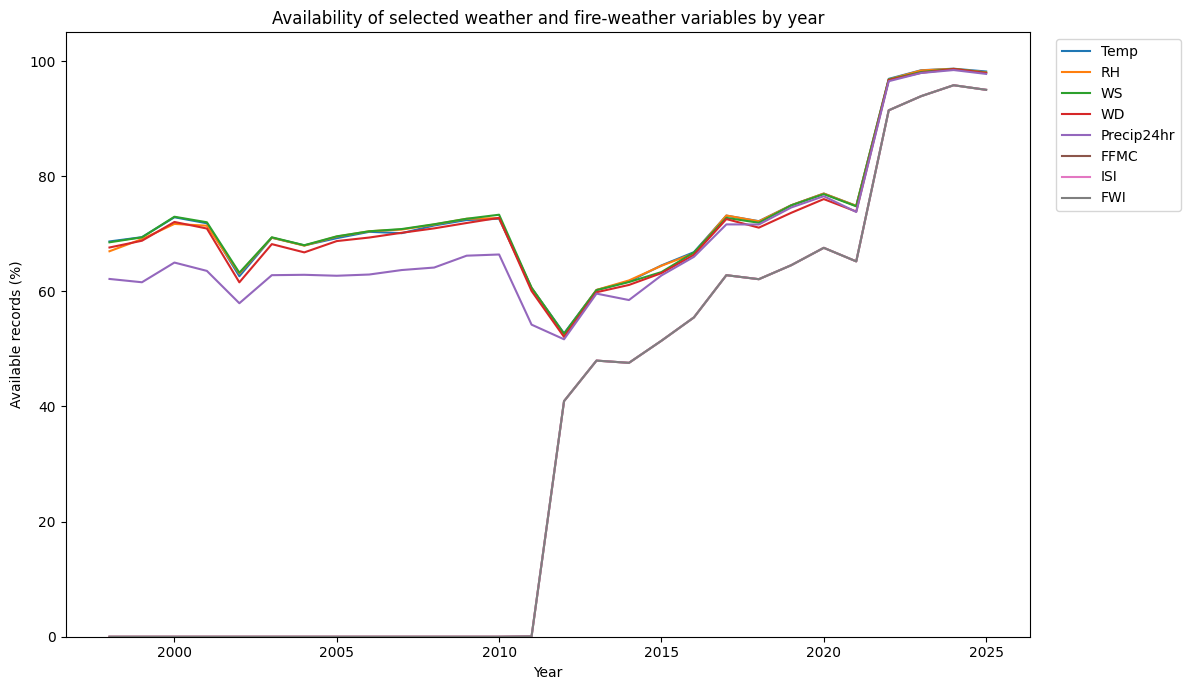

In [38]:
features = [
    "Temp",
    "RH",
    "WS",
    "WD",
    "Precip24hr",
    "FFMC",
    "ISI",
    "FWI"
]

# Calculate percentage of available values for each feature by year
availability = (
    df
    .groupby("Year")[features]
    .apply(lambda x: x.notna().mean() * 100)
)

# Plot
plt.figure(figsize=(12, 7))

for feature in features:
    plt.plot(
        availability.index,
        availability[feature],
        label=feature
    )

plt.xlabel("Year")
plt.ylabel("Available records (%)")
plt.title("Availability of selected weather and fire-weather variables by year")

plt.ylim(0, 105)
plt.legend(
    bbox_to_anchor=(1.02, 1),
    loc="upper left"
)

plt.tight_layout()
plt.show()

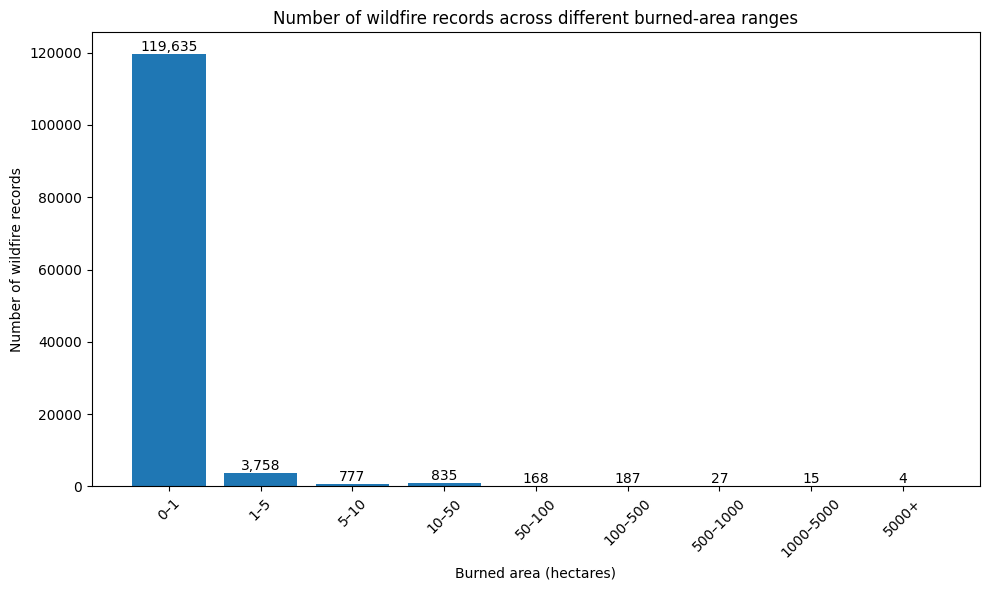

In [39]:
bins = [0, 1, 5, 10, 50, 100, 500, 1000, 5000, float("inf")]
labels = [
    "0–1",
    "1–5",
    "5–10",
    "10–50",
    "50–100",
    "100–500",
    "500–1000",
    "1000–5000",
    "5000+"
]

# Group wildfire records by burned-area range
fire_size_ranges = pd.cut(
    df["AreaHa"],
    bins=bins,
    labels=labels,
    right=False
)

# Count records in each range
size_counts = fire_size_ranges.value_counts().sort_index()

# Plot
plt.figure(figsize=(10, 6))

bars = plt.bar(
    size_counts.index,
    size_counts.values
)

plt.xlabel("Burned area (hectares)")
plt.ylabel("Number of wildfire records")
plt.title("Number of wildfire records across different burned-area ranges")

# Add count labels above bars
for bar in bars:
    height = bar.get_height()
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        height,
        f"{int(height):,}",
        ha="center",
        va="bottom"
    )

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

((array([-4.39545038, -4.19880644, -4.09192566, ...,  4.09192566,
          4.19880644,  4.39545038], shape=(125407,)),
  array([-1.0000e-04,  0.0000e+00,  0.0000e+00, ...,  5.0888e+03,
          5.6000e+03,  6.1590e+03], shape=(125407,))),
 (np.float64(3.766006620837243),
  np.float64(1.1567848983426763),
  np.float64(0.0951196260656166)))

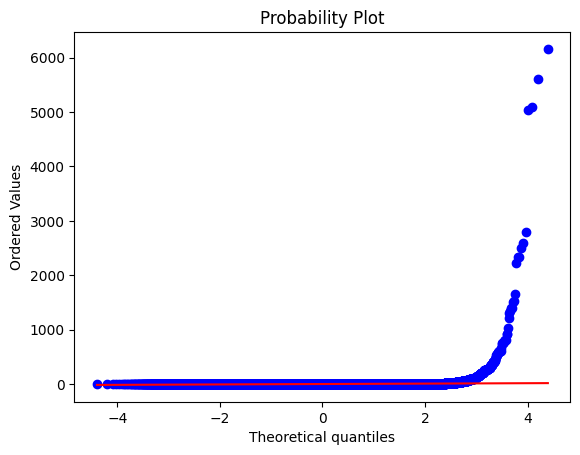

In [40]:
# sns.distplot(df["AreaHa"])

stats.probplot(df["AreaHa"], dist="norm", plot=plt)

#### Preprocessing on Target Variable (AreaHa)

In [126]:
print("Missing target values:", df["AreaHa"].isna().sum())
print("Negative target values:", (df["AreaHa"] < 0).sum())
print("Zero-area records:", (df["AreaHa"] == 0).sum())

display(df.loc[df["AreaHa"] < 0, ["AreaHa"]])

Missing target values: 0
Negative target values: 1
Zero-area records: 28273


,AreaHa
97794,-0.00


In [127]:
# Inspect the original WOD record
negative_index = df[df["AreaHa"] < 0].index

display(
    raw_df.loc[
        raw_df["AreaHa"] < 0,
        ["ID", "Year", "Month", "FuelType", "AreaHa"]
    ]
)

,ID,Year,Month,FuelType,AreaHa
97794,WOD68255,2018,11,Non-Fuel,-0.00


In [128]:
df = df[df["AreaHa"].notna() & (df["AreaHa"] >= 0)]
df.shape, raw_df.shape

((128019, 28), (128020, 109))

In [129]:
# Compare zero and positive burned-area records
print("Zero-area records:", (df["AreaHa"] == 0).sum())
print("Positive-area records:", (df["AreaHa"] > 0).sum())

# Check zero-area records by year
zero_area_by_year = (
    df[df["AreaHa"] == 0]
    .groupby("Year")
    .size()
)

display(zero_area_by_year)

Zero-area records: 28273
Positive-area records: 99746


Year
1931     1
1945     2
1951     1
1957     1
1959     1
        ..
2020     2
2021     2
2022    28
2024     2
2025     1
Length: 67, dtype: int64

In [130]:
df["AreaHa"].describe()

count   128019.00
mean         1.65
std         48.28
min          0.00
25%          0.00
50%          0.00
75%          0.00
max       6159.00
Name: AreaHa, dtype: float64

In [131]:
print("AreaHa summary:")
print(df["AreaHa"].describe())

print("\nSkewness of original AreaHa:",
      df["AreaHa"].skew())

print("\nSkewness of log1p(AreaHa):",
      np.log1p(df["AreaHa"]).skew())

print("\nLargest 10 recorded fire areas:")
print(df["AreaHa"].nlargest(10).to_list())

AreaHa summary:
count   128019.00
mean         1.65
std         48.28
min          0.00
25%          0.00
50%          0.00
75%          0.00
max       6159.00
Name: AreaHa, dtype: float64

Skewness of original AreaHa: 82.41833574387064

Skewness of log1p(AreaHa): 6.891428796865636

Largest 10 recorded fire areas:
[6159.0, 6010.0, 5600.0, 5088.8, 5033.0, 4146.0, 3345.0, 2991.0, 2800.0, 2600.0]


#### Understanding Useful Features

In [132]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 128019 entries, 0 to 128019
Data columns (total 28 columns):
 #   Column      Non-Null Count   Dtype  
---  ------      --------------   -----  
 0   Temp        90679 non-null   float64
 1   RH          90644 non-null   float64
 2   WS          90715 non-null   float64
 3   WD          89837 non-null   float64
 4   FFMC        39740 non-null   float64
 5   ISI         39740 non-null   float64
 6   FWI         39740 non-null   float64
 7   Precip24hr  85765 non-null   float64
 8   NoRain1     94271 non-null   float64
 9   NoRain2     93965 non-null   float64
 10  NoRain3     93692 non-null   float64
 11  FuelType    128019 non-null  object 
 12  FuelClass   128019 non-null  object 
 13  LandCvr     128019 non-null  object 
 14  Elev        127033 non-null  float64
 15  Slope       127109 non-null  float64
 16  AspectDeg   123970 non-null  float64
 17  Landform    128019 non-null  object 
 18  Lat         128019 non-null  float64
 19  Lon    

In [133]:

numeric_cols = df.select_dtypes(include="number").columns

numeric_summary = pd.DataFrame({
    "Missing (%)": (df[numeric_cols].isna().mean() * 100).round(2),
    "Unique Values": df[numeric_cols].nunique(),
    "Min": df[numeric_cols].min(),
    "Median": df[numeric_cols].median(),
    "Max": df[numeric_cols].max(),
    "Skewness": df[numeric_cols].skew()
}).round(3)

display(numeric_summary)


,Missing (%),Unique Values,Min,Median,Max,Skewness
Temp,29.17,451,-32.90,17.20,48.00,-0.33
RH,29.19,100,0.00,66.00,100.00,-0.23
WS,29.14,1260,0.00,3.30,38.52,1.86
WD,29.83,361,0.00,209.00,360.00,-0.20
FFMC,68.96,38675,0.00,81.98,101.00,-2.75
ISI,68.96,38660,0.00,2.59,122.32,4.99
FWI,68.96,38637,0.00,4.72,102.85,2.70
Precip24hr,33.01,404,0.00,0.00,194.40,14.28
NoRain1,26.36,91,0.00,4.00,90.00,1.91
NoRain2,26.60,91,0.00,8.00,90.00,1.75


##### 1.) Variable - Temp 

In [134]:
print("Missing values:", df["Temp"].isna().sum())
print("Minimum:", df["Temp"].min())
print("Maximum:", df["Temp"].max())

print("\nLowest 10 temperature values:")
print(df["Temp"].nsmallest(10))

print("\nHighest 10 temperature values:")
print(df["Temp"].nlargest(10))

Missing values: 37340
Minimum: -32.9
Maximum: 48.0

Lowest 10 temperature values:
36859   -32.90
6985    -32.30
9278    -29.50
39977   -28.30
14617   -24.50
34183   -24.50
34120   -24.20
34181   -24.10
34185   -24.00
34171   -23.80
Name: Temp, dtype: float64

Highest 10 temperature values:
41442   48.00
41457   47.80
67366   47.50
41443   46.70
23242   43.20
23245   43.20
48854   42.90
3477    42.20
7481    41.80
50430   40.70
Name: Temp, dtype: float64


In [135]:
# Inspect unusually low and high temperatures
temp_extremes = df[
    (df["Temp"] < -10) |
    (df["Temp"] > 40)
].sort_values("Temp")

display(temp_extremes[
    ["Year", "Month", "Day", "Temp", "RH", "WS", "Lat", "Lon", "AreaHa"]
])

,Year,Month,Day,Temp,RH,WS,Lat,Lon,AreaHa
36859,2000,8,29,-32.90,0.00,6.40,-45.90,169.20,0.00
6985,2002,10,5,-32.30,9.00,4.30,-37.12,174.79,0.00
9278,2003,12,19,-29.50,91.00,3.00,-35.74,174.26,0.00
39977,2002,10,15,-28.30,36.00,2.70,-42.91,172.63,1.00
34183,2008,9,5,-24.50,100.00,8.50,-38.99,174.23,0.00
14617,2006,10,12,-24.50,62.00,5.80,-35.86,174.20,5.00
34120,2008,8,30,-24.20,100.00,3.10,-39.07,174.07,0.00
34181,2008,9,5,-24.10,100.00,6.30,-39.06,174.07,0.00
34185,2008,9,6,-24.00,100.00,8.50,-39.03,174.17,0.00
34171,2008,9,3,-23.80,100.00,3.50,-39.04,174.12,0.00


##### 2) Variable - RH (Relative Humidity)

In [136]:
print("Missing values:", df["RH"].isna().sum())
print("Missing percentage:", round(df["RH"].isna().mean() * 100, 2), "%")

print("\nLowest RH values:")
print(df["RH"].nsmallest(10))

print("\nHighest RH values:")
print(df["RH"].nlargest(10))

Missing values: 37375
Missing percentage: 29.19 %

Lowest RH values:
2496    0.00
2503    0.00
3539    0.00
3995    0.00
5069    0.00
5100    0.00
5105    0.00
5109    0.00
6927    0.00
34700   0.00
Name: RH, dtype: float64

Highest RH values:
30     100.00
1197   100.00
1326   100.00
1441   100.00
1446   100.00
1456   100.00
1588   100.00
1605   100.00
1613   100.00
1625   100.00
Name: RH, dtype: float64


##### 3) Variable - WS (Wind Speed)

In [137]:
df["WS"].describe()

count   90715.00
mean        3.96
std         2.96
min         0.00
25%         1.90
50%         3.30
75%         5.14
max        38.52
Name: WS, dtype: float64

In [138]:
print("Missing values:", df["WS"].isna().sum())
print("Missing percentage:", round(df["WS"].isna().mean() * 100, 2), "%")

print("\nLowest WS values:")
print(df["WS"].nsmallest(10))

print("\nHighest WS values:")
print(df["WS"].nlargest(10))

Missing values: 37304
Missing percentage: 29.14 %

Lowest WS values:
103    0.00
402    0.00
416    0.00
456    0.00
489    0.00
765    0.00
941    0.00
964    0.00
970    0.00
1043   0.00
Name: WS, dtype: float64

Highest WS values:
126688   38.52
74498    37.10
112107   36.90
126700   33.19
34528    32.30
96859    32.19
74507    29.40
74511    29.40
85208    29.20
74596    28.97
Name: WS, dtype: float64


##### 4) Variable - WD (Wind Direction)

In [139]:
df["WD"].describe()

count   89837.00
mean      185.33
std       108.32
min         0.00
25%        80.00
50%       209.00
75%       274.00
max       360.00
Name: WD, dtype: float64

In [140]:
print("Missing values:", df["WD"].isna().sum())
print("Missing percentage:", round(df["WD"].isna().mean() * 100, 2), "%")

print("\nLowest WD values:")
print(df["WD"].nsmallest(10))

print("\nHighest WD values:")
print(df["WD"].nlargest(10))

Missing values: 38182
Missing percentage: 29.83 %

Lowest WD values:
314    0.00
787    0.00
828    0.00
949    0.00
959    0.00
960    0.00
966    0.00
1180   0.00
1244   0.00
1456   0.00
Name: WD, dtype: float64

Highest WD values:
99     360.00
1121   360.00
1695   360.00
2104   360.00
3275   360.00
3389   360.00
3397   360.00
4406   360.00
4438   360.00
4882   360.00
Name: WD, dtype: float64


##### 5) Variables - weather_codes ("FFMC", "ISI", "FWI")

In [141]:
weather_codes = ["FFMC", "ISI", "FWI"]

print("Missing values per feature:")
print(df[weather_codes].isna().sum())

print("\nRows where all three are missing:")
print(df[weather_codes].isna().all(axis=1).sum())

print("\nRows where all three are available:")
print(df[weather_codes].notna().all(axis=1).sum())

print("\nRows where only some are missing:")
print(
    (
        df[weather_codes].isna().any(axis=1)
        & ~df[weather_codes].isna().all(axis=1)
    ).sum()
)


Missing values per feature:
FFMC    88279
ISI     88279
FWI     88279
dtype: int64

Rows where all three are missing:
88279

Rows where all three are available:
39740

Rows where only some are missing:
0


In [142]:
df.groupby("Year")[["FFMC", "ISI", "FWI"]].apply(
    lambda group: group.isna().any(axis=1).mean() * 100
).rename("Missing (%)").round(2).to_frame()


,Missing (%)
Year,
1931,100.00
1932,100.00
1943,100.00
1945,100.00
1946,100.00
...,...
2021,34.79
2022,8.55
2023,6.09


In [143]:
year_coverage = df.groupby("Year").agg(
    Total_Records=("Year", "size"),
    Weather_Records=("FFMC", "count")
)

year_coverage["Weather_Missing (%)"] = (
    100 * (1 - year_coverage["Weather_Records"] / year_coverage["Total_Records"])
).round(2)

display(year_coverage)


,Total_Records,Weather_Records,Weather_Missing (%)
Year,,,
1931,2,0,100.00
1932,2,0,100.00
1943,1,0,100.00
1945,2,0,100.00
1946,2,0,100.00
...,...,...,...
2021,4159,2712,34.79
2022,3696,3380,8.55
2023,3155,2963,6.09


##### 6) Variable - Precip24hr

In [144]:
print("Zero values:", (df["Precip24hr"] == 0).sum())
print("Negative values:", (df["Precip24hr"] < 0).sum())

print("\nLowest values:")
print(df["Precip24hr"].nsmallest(10))

print("\nHighest values:")
print(df["Precip24hr"].nlargest(10))

Zero values: 63407
Negative values: 0

Lowest values:
5    0.00
7    0.00
9    0.00
14   0.00
15   0.00
16   0.00
17   0.00
24   0.00
25   0.00
26   0.00
Name: Precip24hr, dtype: float64

Highest values:
87133    194.40
100597   186.40
16178    152.40
118002   148.00
89186    146.80
45786    127.80
108514   125.50
12474    124.80
31806    121.20
117585   115.40
Name: Precip24hr, dtype: float64


In [145]:
cols = [
    "Year", "Month", "Day",
    "Precip24hr", "Temp", "RH", "WS",
    "AreaHa"
]

display(
    df.loc[
        df["Precip24hr"].nlargest(10).index,
        cols
    ].sort_values("Precip24hr", ascending=False)
)

,Year,Month,Day,Precip24hr,Temp,RH,WS,AreaHa
87133,2016,1,19,194.40,22.70,80.00,6.40,0.00
100597,2019,5,13,186.40,18.40,77.00,NaN,0.00
16178,2007,3,30,152.40,22.50,66.00,5.10,0.00
118002,2023,2,14,148.00,17.10,100.00,8.60,0.00
89186,2016,7,23,146.80,14.30,99.00,9.20,0.00
45786,2006,4,26,127.80,7.20,93.00,12.40,0.00
108514,2020,11,8,125.50,21.50,58.00,3.10,0.00
12474,2005,10,3,124.80,13.20,95.00,1.30,0.00
31806,2010,12,24,121.20,22.40,59.00,7.40,0.00
117585,2023,1,4,115.40,18.80,99.00,9.80,0.00


##### 7) Variables- NoRain1, NoRain2, and NoRain3

In [146]:
cols = ["NoRain1", "NoRain2", "NoRain3"]

# Summary statistics
display(df[cols].describe().T)

# Missing values
print("\nMissing values:")
print(df[cols].isna().sum())

print("\nMissing percentage:")
print((df[cols].isna().mean() * 100).round(2))

# Zero and negative values
print("\nZero values:")
print((df[cols] == 0).sum())

print("\nNegative values:")
print((df[cols] < 0).sum())

# Lowest and highest values
for col in cols:
    print(f"\n{col} - lowest values:")
    print(df[col].nsmallest(10).to_list())

    print(f"{col} - highest values:")
    print(df[col].nlargest(10).to_list())


,count,mean,std,min,25%,50%,75%,max
NoRain1,94271.00,12.48,19.41,0.00,2.00,4.00,10.00,90.00
NoRain2,93965.00,16.21,19.50,0.00,4.00,8.00,17.00,90.00
NoRain3,93692.00,19.88,19.62,0.00,7.00,12.00,23.00,90.00



Missing values:
NoRain1    33748
NoRain2    34054
NoRain3    34327
dtype: int64

Missing percentage:
NoRain1   26.36
NoRain2   26.60
NoRain3   26.81
dtype: float64

Zero values:
NoRain1    12174
NoRain2       20
NoRain3        1
dtype: int64

Negative values:
NoRain1    0
NoRain2    0
NoRain3    0
dtype: int64

NoRain1 - lowest values:
[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0]
NoRain1 - highest values:
[90.0, 90.0, 90.0, 89.0, 89.0, 89.0, 89.0, 89.0, 89.0, 89.0]

NoRain2 - lowest values:
[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0]
NoRain2 - highest values:
[90.0, 90.0, 90.0, 90.0, 89.0, 89.0, 89.0, 89.0, 89.0, 89.0]

NoRain3 - lowest values:
[0.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0]
NoRain3 - highest values:
[90.0, 90.0, 90.0, 90.0, 90.0, 90.0, 90.0, 90.0, 90.0, 90.0]


In [147]:
cols = ["NoRain1", "NoRain2", "NoRain3"]

print("Correlation between the three features:")
display(df[cols].corr().round(3))


Correlation between the three features:


,NoRain1,NoRain2,NoRain3
NoRain1,1.00,0.97,0.94
NoRain2,0.97,1.00,0.97
NoRain3,0.94,0.97,1.00


##### 8) Variable - Elev and Slope

In [148]:
cols = ["Elev", "Slope"]

display(df[cols].describe().T)

for col in cols:
    print(f"\n{col} - lowest values:")
    print(df[col].nsmallest(10).to_list())

    print(f"{col} - highest values:")
    print(df[col].nlargest(10).to_list())


,count,mean,std,min,25%,50%,75%,max
Elev,127033.00,88.47,132.82,-8.93,14.32,36.26,100.52,2313.61
Slope,127109.00,2.62,4.40,0.00,0.00,1.00,3.00,48.00



Elev - lowest values:
[-8.92643928527832, -1.83339095115662, -1.80705738067627, -1.2188423871994, -0.844179451465607, -0.844179451465607, -0.779837429523468, -0.695966184139252, -0.695966184139252, -0.695966184139252]
Elev - highest values:
[2313.61157226562, 2032.37548828125, 1862.44470214844, 1688.06481933594, 1639.11584472656, 1616.49914550781, 1601.88562011719, 1594.16857910156, 1572.892578125, 1563.22595214844]

Slope - lowest values:
[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0]
Slope - highest values:
[48.0, 43.0, 42.0, 42.0, 41.0, 41.0, 41.0, 41.0, 40.0, 40.0]


##### 9) Variable - SOI

In [149]:
print(df["SOI"].describe())

print("\nMissing values:", df["SOI"].isna().sum())

print("\nLowest values:")
print(df["SOI"].nsmallest(10).to_list())

print("\nHighest values:")
print(df["SOI"].nlargest(10).to_list())

count   127976.00
mean         1.97
std         10.09
min        -33.30
25%         -5.50
50%          1.30
75%          9.40
max         27.10
Name: SOI, dtype: float64

Missing values: 43

Lowest values:
[-33.3, -33.3, -33.3, -33.3, -33.3, -33.3, -33.3, -33.3, -33.3, -31.1]

Highest values:
[27.1, 27.1, 27.1, 27.1, 27.1, 27.1, 27.1, 27.1, 27.1, 27.1]


##### 10) Variables - LandCvr, FuelClass, Landform, FENZDist, FuelType, and ENSO

In [150]:
categorical_cols = [
    "LandCvr", "FuelClass", "Landform",
    "FENZDist", "FuelType", "ENSO"
]

for col in categorical_cols:
    print(f"\n--- {col} ---")
    print("Unique categories:", df[col].nunique())
    print(df[col].value_counts(dropna=False).head(15))



--- LandCvr ---
Unique categories: 102
LandCvr
Built-up Area (settlement)                   48323
High Producing Exotic Grassland              46171
Urban Parkland/Open Space                     7291
Short-rotation Cropland                       3383
Exotic Forest                                 3340
Low Producing Grassland                       2450
Indigenous Forest                             2103
Orchard, Vineyard or Other Perennial Crop     1890
Broadleaved Indigenous Hardwoods              1816
Manuka and/or Kanuka                          1578
-9999                                         1275
Transport Infrastructure                       952
Sand or Gravel                                 950
Deciduous Hardwoods                            939
Gorse and/or Broom                             930
Name: count, dtype: int64

--- FuelClass ---
Unique categories: 5
FuelClass
Grass       62355
Non Fuel    51595
Scrub        6484
Forest       6308
-9999        1277
Name: count, dtype: i

In [151]:
for col in df.columns:
    count = (df[col].astype(str).str.strip() == "-9999").sum()
    if count > 0:
        print(f"{col}: {count}")


FuelType: 1277
FuelClass: 1277
LandCvr: 1275
Landform: 2926
FENZDist: 92
ENSO: 43


In [152]:
categorical_cols = [
    "LandCvr", "FuelClass", "Landform",
    "FENZDist", "FuelType", "ENSO"
]

for col in categorical_cols:
    df[col] = df[col].replace("-9999", np.nan)

print("Missing values after replacement:")
display(df[categorical_cols].isna().sum())


Missing values after replacement:


LandCvr      1275
FuelClass    1277
Landform     2926
FENZDist       92
FuelType     1277
ENSO           43
dtype: int64

##### 11) Variables - Year, Month, Day, and Hour

In [153]:
time_cols = ["Year", "Month", "Day", "Hour"]

print("Summary statistics:")
display(df[time_cols].describe().T)

print("\nMissing values:")
display(df[time_cols].isna().sum())

print("\nUnique values:")
display(df[time_cols].nunique())

print("\nValues outside expected ranges:")
print("Month outside 1–12:", (~df["Month"].between(1, 12)).sum())
print("Day outside 1–31:", (~df["Day"].between(1, 31)).sum())
print("Hour outside 0–23:", (~df["Hour"].dropna().between(0, 23)).sum())


Summary statistics:


,count,mean,std,min,25%,50%,75%,max
Year,128019.00,2010.84,8.36,1931.00,2005.00,2011.00,2018.00,2025.00
Month,128019.00,6.29,4.03,1.00,2.00,6.00,11.00,12.00
Day,128019.00,15.32,8.95,1.00,7.00,15.00,23.00,31.00
Hour,122537.00,14.37,5.22,0.00,12.00,15.00,18.00,23.00



Missing values:


Year        0
Month       0
Day         0
Hour     5482
dtype: int64


Unique values:


Year     78
Month    12
Day      31
Hour     24
dtype: int64


Values outside expected ranges:
Month outside 1–12: 0
Day outside 1–31: 0
Hour outside 0–23: 0


##### 12) Variables - Lat, Lon, and AspectDeg

In [154]:
cols = ["Lat", "Lon", "AspectDeg"]

print("Summary statistics:")
display(df[cols].describe().T)

print("\nMissing values:")
display(df[cols].isna().sum())

print("\nValues outside expected ranges:")
print("Latitude outside -90 to 90:", (~df["Lat"].between(-90, 90)).sum())
print("Longitude outside -180 to 180:", (~df["Lon"].between(-180, 180)).sum())
print("AspectDeg outside 0 to 360:", (~df["AspectDeg"].between(0, 360)).sum())


Summary statistics:


,count,mean,std,min,25%,50%,75%,max
Lat,128019.00,-40.06,3.20,-47.21,-43.33,-39.60,-37.11,-34.16
Lon,128019.00,173.95,4.68,-176.61,172.66,174.70,175.32,178.97
AspectDeg,123970.00,175.23,92.77,0.00,99.16,165.33,255.88,359.74



Missing values:


Lat             0
Lon             0
AspectDeg    4049
dtype: int64


Values outside expected ranges:
Latitude outside -90 to 90: 0
Longitude outside -180 to 180: 0
AspectDeg outside 0 to 360: 4049


In [155]:
aspect = df["AspectDeg"].dropna()

print("Missing AspectDeg:", df["AspectDeg"].isna().sum())
print("Below 0:", (aspect < 0).sum())
print("Above 360:", (aspect > 360).sum())
print("Exactly 360:", (aspect == 360).sum())

Missing AspectDeg: 4049
Below 0: 0
Above 360: 0
Exactly 360: 0


#### Finalising Dependent Features

In [156]:
print("Duplicate rows:", df.duplicated().sum())

# Check duplicate combinations of location and date
fire_key = ["Lat", "Lon", "Year", "Month", "Day"]

print(
    "Duplicate location-date combinations:",
    df.duplicated(subset=fire_key).sum()
)

Duplicate rows: 22
Duplicate location-date combinations: 672


In [157]:
df[df.duplicated(keep=False)].sort_values(by=["Year", "Month", "Day"])

,Temp,RH,WS,WD,FFMC,ISI,FWI,Precip24hr,NoRain1,NoRain2,...,Lat,Lon,FENZDist,Day,Month,Hour,Year,SOI,ENSO,AreaHa
34854,1.60,92.00,0.90,293.00,NaN,NaN,NaN,0.80,0.00,1.00,...,-46.42,168.36,Southland,21,11,3.00,1998,12.50,La Nina,0.00
34855,1.60,92.00,0.90,293.00,NaN,NaN,NaN,0.80,0.00,1.00,...,-46.42,168.36,Southland,21,11,3.00,1998,12.50,La Nina,0.00
589,25.00,46.00,2.50,306.00,NaN,NaN,NaN,0.00,5.00,6.00,...,-36.77,174.75,Auckland,16,12,15.00,1998,13.30,La Nina,0.00
590,25.00,46.00,2.50,306.00,NaN,NaN,NaN,0.00,5.00,6.00,...,-36.77,174.75,Auckland,16,12,15.00,1998,13.30,La Nina,0.00
34983,10.90,91.00,2.00,333.00,NaN,NaN,NaN,0.00,3.00,5.00,...,-46.40,168.35,Southland,26,12,0.00,1998,13.30,La Nina,0.00
34984,10.90,91.00,2.00,333.00,NaN,NaN,NaN,0.00,3.00,5.00,...,-46.40,168.35,Southland,26,12,0.00,1998,13.30,La Nina,0.00
774,25.50,56.00,4.10,270.00,NaN,NaN,NaN,0.00,17.00,18.00,...,-38.24,175.88,Bay of Plenty,5,1,19.00,1999,15.60,La Nina,0.00
775,25.50,56.00,4.10,270.00,NaN,NaN,NaN,0.00,17.00,18.00,...,-38.24,175.88,Bay of Plenty,5,1,19.00,1999,15.60,La Nina,0.00
1157,26.90,55.00,2.99,NaN,NaN,NaN,NaN,0.10,12.00,20.00,...,-36.63,174.72,Auckland,21,2,13.00,1999,8.60,La Nina,0.00
1158,26.90,55.00,2.99,NaN,NaN,NaN,NaN,0.10,12.00,20.00,...,-36.63,174.72,Auckland,21,2,13.00,1999,8.60,La Nina,0.00


In [158]:
print("Rows before:", len(df))

df = df.drop_duplicates().copy()

print("Rows after:", len(df))
print("Exact duplicates remaining:", df.duplicated().sum())

Rows before: 128019
Rows after: 127997
Exact duplicates remaining: 0


#### Train-Test Split

In [159]:
df = df[df["Year"] >= 1998]

In [160]:
# Get distinct years in chronological order
years = np.sort(df["Year"].unique())

# Reserve the final 20% of years for testing
split_year_idx = int(len(years) * 0.80)
test_start_year = years[split_year_idx]

# Split by year, not by individual rows
train_df = df[df["Year"] < test_start_year].copy()
test_df = df[df["Year"] >= test_start_year].copy()

# Separate features and target
target = "AreaHa"

X_train = train_df.drop(columns=[target])
y_train = train_df[target]

X_test = test_df.drop(columns=[target])
y_test = test_df[target]

In [161]:
print("Training set:", X_train.shape)
print("Test set:", X_test.shape)

print(
    f"Training years: {train_df['Year'].min()} "
    f"to {train_df['Year'].max()}"
)

print(
    f"Test years: {test_df['Year'].min()} "
    f"to {test_df['Year'].max()}"
)

print("\nTarget missing values:")
print("Training:", y_train.isna().sum())
print("Test:", y_test.isna().sum())

Training set: (101241, 27)
Test set: (24143, 27)
Training years: 1998 to 2019
Test years: 2020 to 2025

Target missing values:
Training: 0
Test: 0


#### Implementing ML Pipeline 

In [162]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.preprocessing import StandardScaler
from sklearn.preprocessing import FunctionTransformer

##### 1) Keeping Only Useful Features

In [179]:
# Useful Features
features = [
    # Weather at detection
    "Temp", "RH", "WS", "WD",
    # Fire-weather indices
    "FFMC", "ISI", "FWI",
    # Recent rainfall and drying
    "Precip24hr", "NoRain1", "NoRain2", "NoRain3",
    # Fuel and land cover
    "FuelClass", "LandCvr",
    # Topography
    "Elev", "Slope", "AspectDeg", "Landform",
    # Location and time
    "Lat", "Lon", "FENZDist",
    "Day", "Month", "Hour", "Year",
    # Climate
    "SOI", "ENSO"
]

trf1 = FunctionTransformer(
    lambda x: x[features].copy()
)

X_train_temp = trf1.fit_transform(X_train)
X_train_temp.sample(1)

,Temp,RH,WS,WD,FFMC,ISI,FWI,Precip24hr,NoRain1,NoRain2,...,Landform,Lat,Lon,FENZDist,Day,Month,Hour,Year,SOI,ENSO
8067,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,Valley,-37.93,176.98,Bay of Plenty,18,2,19.00,2003,-7.40,Neutral


##### 2) Caping inaccurate Values

In [180]:
df.describe()

,Temp,RH,WS,WD,FFMC,ISI,FWI,Precip24hr,NoRain1,NoRain2,...,Slope,AspectDeg,Lat,Lon,Day,Month,Hour,Year,SOI,AreaHa
count,90528.00,90494.00,90564.00,89692.00,39736.00,39736.00,39736.00,85622.00,94086.00,93781.00,...,124605.00,121513.00,125384.00,125384.00,125384.00,125384.00,122515.00,125384.00,125341.00,125384.00
mean,17.00,65.91,3.96,185.29,77.19,4.02,7.55,0.85,12.48,16.22,...,2.49,175.01,-40.05,173.95,15.31,6.28,14.37,2011.33,2.08,1.16
std,5.51,17.99,2.96,108.32,14.94,5.46,9.11,3.89,19.42,19.51,...,4.16,92.70,3.20,4.61,8.95,4.03,5.22,7.62,10.06,39.59
min,-32.90,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,...,0.00,0.00,-47.21,-176.61,1.00,1.00,0.00,1998.00,-28.60,0.00
25%,13.50,54.00,1.90,80.00,77.23,1.47,1.28,0.00,2.00,4.00,...,0.00,99.06,-43.35,172.66,7.00,2.00,12.00,2005.00,-5.50,0.00
50%,17.20,66.00,3.30,209.00,81.98,2.59,4.72,0.00,4.00,8.00,...,1.00,164.96,-39.59,174.70,15.00,5.00,15.00,2011.00,1.30,0.00
75%,20.90,79.00,5.14,274.00,84.68,4.43,10.22,0.20,10.00,17.00,...,3.00,255.45,-37.08,175.31,23.00,11.00,18.00,2018.00,9.40,0.00
max,48.00,100.00,38.52,360.00,101.00,122.32,102.85,194.40,90.00,90.00,...,43.00,359.74,-34.16,178.97,31.00,12.00,23.00,2025.00,27.10,6159.00


In [181]:
trf2 = FunctionTransformer(
    lambda X: X.assign(
        # Weather at detection
        Temp=np.where(
            (X["Temp"] >= -33) & (X["Temp"] <= 48),
            X["Temp"], np.nan
        ),
        RH=np.where(
            (X["RH"] >= 0) & (X["RH"] <= 100),
            X["RH"], np.nan
        ),
        WS=np.where(
            (X["WS"] >= 0) & (X["WS"] <= 150),
            X["WS"], np.nan
        ),
        WD=np.where(
            (X["WD"] >= 0) & (X["WD"] <= 360),
            X["WD"], np.nan
        ),

        # Fire-weather indices
        FFMC=np.where(
            (X["FFMC"] >= 0) & (X["FFMC"] <= 101),
            X["FFMC"], np.nan
        ),
        ISI=np.where(
            (X["ISI"] >= 0) & (X["ISI"] <= 100),
            X["ISI"], np.nan
        ),
        FWI=np.where(
            (X["FWI"] >= 0) & (X["FWI"] <= 150),
            X["FWI"], np.nan
        ),

        # Recent rainfall and drying
        Precip24hr=np.where(
            X["Precip24hr"] >= 0,
            X["Precip24hr"], np.nan
        ),
        NoRain1=np.where(
            X["NoRain1"] >= 0,
            X["NoRain1"], np.nan
        ),
        NoRain2=np.where(
            X["NoRain2"] >= 0,
            X["NoRain2"], np.nan
        ),
        NoRain3=np.where(
            X["NoRain3"] >= 0,
            X["NoRain3"], np.nan
        ),

        # Topography
        Elev=np.where(
            X["Elev"] >= -500,
            X["Elev"], np.nan
        ),
        Slope=np.where(
            (X["Slope"] >= 0) & (X["Slope"] <= 90),
            X["Slope"], np.nan
        ),
        AspectDeg=np.where(
            (X["AspectDeg"] >= 0) & (X["AspectDeg"] <= 360),
            X["AspectDeg"], np.nan
        ),

        # Location
        Lat=np.where(
            (X["Lat"] >= -90) & (X["Lat"] <= 90),
            X["Lat"], np.nan
        ),
        Lon=np.where(
            (X["Lon"] >= -180) & (X["Lon"] <= 180),
            X["Lon"], np.nan
        ),

        # Time
        Day=np.where(
            (X["Day"] >= 1) & (X["Day"] <= 31),
            X["Day"], np.nan
        ),
        Month=np.where(
            (X["Month"] >= 1) & (X["Month"] <= 12),
            X["Month"], np.nan
        ),
        Hour=np.where(
            (X["Hour"] >= 0) & (X["Hour"] <= 23),
            X["Hour"], np.nan
        ),
        Year=np.clip(X["Year"], 1998, 2025),
    )
)

X_train_temp = trf2.fit_transform(X_train_temp)

X_train_temp.shape, X_train.shape

((101241, 26), (101241, 27))

##### 3) Handle Missing Values

In [183]:
# Identify numerical and categorical features
numeric_cols = X_train_temp.select_dtypes(
    include=["number"]
).columns.tolist()

categorical_cols = X_train_temp.select_dtypes(
    include=["object", "category", "string"]
).columns.tolist()

print("Numerical features:", numeric_cols)
print("\nCategorical features:", categorical_cols)

Numerical features: ['Temp', 'RH', 'WS', 'WD', 'FFMC', 'ISI', 'FWI', 'Precip24hr', 'NoRain1', 'NoRain2', 'NoRain3', 'Elev', 'Slope', 'AspectDeg', 'Lat', 'Lon', 'Day', 'Month', 'Hour', 'Year', 'SOI']

Categorical features: ['FuelClass', 'LandCvr', 'Landform', 'FENZDist', 'ENSO']


In [184]:
# Handling missing values
trf3 = ColumnTransformer(
    transformers=[
        # Handling missing values on numerical features
        (
            "trf_3_1",
            SimpleImputer(strategy="median"),
            numeric_cols
        ),

        # Handling missing values on categorical features
        (
            "trf_3_2",
            SimpleImputer(strategy="most_frequent"),
            categorical_cols
        )
    ],
    remainder="passthrough",
    verbose_feature_names_out=False
)

trf3.set_output(transform="pandas")

X_train_temp = trf3.fit_transform(X_train_temp)
X_train_temp.sample(5)

,Temp,RH,WS,WD,FFMC,ISI,FWI,Precip24hr,NoRain1,NoRain2,...,Day,Month,Hour,Year,SOI,FuelClass,LandCvr,Landform,FENZDist,ENSO
35351,22.00,67.00,6.12,212.00,81.91,2.57,4.62,0.00,17.00,18.00,...,18.00,2.00,13.00,1999.00,8.60,Grass,High Producing Exotic Grassland,Valley,Nelson Marlborough,La Nina
66108,2.40,75.00,1.40,298.00,81.91,2.57,4.62,0.00,7.00,15.00,...,13.00,8.00,19.00,2011.00,2.10,Grass,High Producing Exotic Grassland,Channel,Otago,La Nina
3643,17.00,66.00,3.30,212.00,81.91,2.57,4.62,0.00,3.00,7.00,...,18.00,9.00,15.00,2000.00,9.90,Non Fuel,Built-up Area (settlement),Valley,Northland,La Nina
98522,22.20,78.00,1.50,228.00,83.73,2.33,6.24,0.00,17.00,18.00,...,11.00,1.00,21.00,2019.00,-0.60,Grass,High Producing Exotic Grassland,Valley,Auckland,Neutral
1165,24.10,56.00,1.40,48.00,81.91,2.57,4.62,0.00,2.00,21.00,...,21.00,2.00,18.00,1999.00,8.60,Non Fuel,Built-up Area (settlement),Valley,Bay of Plenty,La Nina


##### 4) Handling Highly Skewed Features

In [186]:
skew_features = [
    "Precip24hr", "ISI", "NoRain1",
    "NoRain2", "NoRain3", "FWI", "WS"
]

numeric_features = X_train_temp[skew_features].select_dtypes(
    include=np.number
)

skew_values = numeric_features.skew().sort_values(
    ascending=False
)

skew_values

Precip24hr   18.55
ISI          11.68
FWI           7.20
NoRain1       5.23
NoRain2       4.09
NoRain3       3.29
WS            2.40
dtype: float64

In [187]:
trf4 = FunctionTransformer(
    lambda X: X.assign(
        Precip24hr=np.log1p(X["Precip24hr"]),
        ISI=np.log1p(X["ISI"]),
        NoRain1=np.log1p(X["NoRain1"]),
        NoRain2=np.log1p(X["NoRain2"]),
        NoRain3=np.log1p(X["NoRain3"]),
        FWI=np.log1p(X["FWI"]),
        WS=np.log1p(X["WS"])
    )
)

X_train_temp = trf4.fit_transform(X_train_temp)

X_train_temp[skew_features].skew().sort_values(
    ascending=False
)

Precip24hr    3.95
ISI           1.91
NoRain1       0.48
NoRain2       0.35
NoRain3       0.24
WS           -0.15
FWI          -0.16
dtype: float64

##### 5) Applying Circular Encoding 

In [188]:
trf5 = FunctionTransformer(
    lambda X: X.assign(
        WD_sin=np.sin(np.deg2rad(X["WD"])),
        WD_cos=np.cos(np.deg2rad(X["WD"])),
        AspectDeg_sin=np.sin(np.deg2rad(X["AspectDeg"])),
        AspectDeg_cos=np.cos(np.deg2rad(X["AspectDeg"]))
    ).drop(columns=["WD", "AspectDeg"])
)

X_train_temp = trf5.fit_transform(X_train_temp)
X_train_temp.shape, X_train.shape

((101241, 28), (101241, 27))

##### 6) Encoding Month and Hour cyclically

In [189]:
trf6 = FunctionTransformer(
    lambda X: X.assign(
        Month_sin=np.sin(2 * np.pi * (X["Month"] - 1) / 12),
        Month_cos=np.cos(2 * np.pi * (X["Month"] - 1) / 12),
        Hour_sin=np.sin(2 * np.pi * X["Hour"] / 24),
        Hour_cos=np.cos(2 * np.pi * X["Hour"] / 24)
    ).drop(columns=["Month", "Hour"])
)


X_train_temp = trf6.fit_transform(X_train_temp)
X_train_temp.shape, X_train.shape

((101241, 30), (101241, 27))

##### 7) Encoding Categorical Features

In [190]:
# Identify categorical columns after trf5
categorical_cols = X_train_temp.select_dtypes(
    include=["object", "category", "string"]
).columns.tolist()

categorical_cols

['FuelClass', 'LandCvr', 'Landform', 'FENZDist', 'ENSO']

In [191]:
# One-hot encoding
trf7 = ColumnTransformer(
    transformers=[
        (
            "trf_7_1",
            OneHotEncoder(
                handle_unknown="ignore",
                sparse_output=False
            ),
            categorical_cols
        )
    ],
    remainder="passthrough",
    verbose_feature_names_out=False
)

trf7.set_output(transform="pandas")

X_train_temp = trf7.fit_transform(X_train_temp)
X_train_temp.sample(5)

,FuelClass_Forest,FuelClass_Grass,FuelClass_Non Fuel,FuelClass_Scrub,LandCvr_Alpine Grass/Herbfield,LandCvr_Broadleaved Indigenous Hardwoods,LandCvr_Built-up Area (settlement),LandCvr_Deciduous Hardwoods,LandCvr_Depleted Grassland,LandCvr_Estuarine Open Water,...,Year,SOI,WD_sin,WD_cos,AspectDeg_sin,AspectDeg_cos,Month_sin,Month_cos,Hour_sin,Hour_cos
89782,0.00,1.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,...,2016.00,-4.30,-0.93,0.37,0.97,-0.24,-1.00,-0.00,-1.00,-0.00
4201,0.00,0.00,1.00,0.00,0.00,0.00,0.00,0.00,0.00,1.00,...,2000.00,7.70,-0.53,-0.85,-0.68,-0.73,-0.50,0.87,-0.87,-0.50
12723,0.00,1.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,...,2005.00,-2.00,-0.96,-0.29,-0.93,0.37,-0.87,0.50,-0.97,-0.26
18211,0.00,1.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,...,2007.00,9.20,-0.91,-0.41,0.01,-1.00,-0.87,0.50,-0.50,-0.87
100476,0.00,1.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,...,2019.00,-9.00,-0.17,-0.98,0.90,0.43,0.87,-0.50,-0.26,-0.97


##### 8) Scaling features

In [192]:
numeric_cols = [
    col for col in X_train_temp.columns
    if col not in ["FFMC", "ISI", "FWI"]
    and pd.api.types.is_numeric_dtype(X_train_temp[col])
]

trf8 = ColumnTransformer(
    transformers=[
        (
            "trf_8_1",
            StandardScaler(),
            numeric_cols
        )
    ],
    remainder="passthrough",
    verbose_feature_names_out=False
)
trf8.set_output(transform="pandas")

X_train_temp = trf8.fit_transform(X_train_temp)
X_train_temp.sample(5)

,FuelClass_Forest,FuelClass_Grass,FuelClass_Non Fuel,FuelClass_Scrub,LandCvr_Alpine Grass/Herbfield,LandCvr_Broadleaved Indigenous Hardwoods,LandCvr_Built-up Area (settlement),LandCvr_Deciduous Hardwoods,LandCvr_Depleted Grassland,LandCvr_Estuarine Open Water,...,WD_cos,AspectDeg_sin,AspectDeg_cos,Month_sin,Month_cos,Hour_sin,Hour_cos,FFMC,ISI,FWI
46646,-0.21,-0.95,1.14,-0.22,-0.01,-0.12,-0.85,-0.09,-0.02,-0.04,...,0.83,-1.01,-0.90,-1.13,0.30,1.14,-1.06,81.91,1.27,1.73
19357,-0.21,1.05,-0.88,-0.22,-0.01,-0.12,-0.85,-0.09,-0.02,-0.04,...,1.00,1.25,0.44,-0.62,0.89,-0.80,1.17,81.91,1.27,1.73
72938,4.71,-0.95,-0.88,-0.22,-0.01,-0.12,-0.85,-0.09,-0.02,-0.04,...,-0.89,1.07,1.00,1.30,0.30,0.25,1.88,81.91,1.27,1.73
65672,-0.21,1.05,-0.88,-0.22,-0.01,-0.12,-0.85,-0.09,-0.02,-0.04,...,-0.97,0.10,-1.26,1.30,-1.30,1.14,1.88,81.91,1.27,1.73
75895,-0.21,1.05,-0.88,-0.22,-0.01,-0.12,-0.85,-0.09,-0.02,-0.04,...,-0.89,-0.53,1.67,-0.62,0.89,-0.17,1.72,81.91,1.27,1.73


##### 9) Machine Learning Model

In [193]:
from sklearn.linear_model import LinearRegression

trf9 = LinearRegression()

##### 10) Pipeline Implementation and Model Fit

In [194]:
pipe = Pipeline([
    ("trf1", trf1),
    ("trf2", trf2),
    ("trf3", trf3),
    ("trf4", trf4),
    ("trf5", trf5),
    ("trf6", trf6),
    ("trf7", trf7),
    ("trf8", trf8),
    ("trf9", trf9)
])

In [195]:
# train the pipeline

pipe.fit(X_train, np.log1p(y_train))

,steps,"[('trf1', ...), ('trf2', ...), ...]"
,transform_input,None
,memory,None
,verbose,False
,func,<function <la...0026291DE9080>
,inverse_func,None
,validate,False
,accept_sparse,False
,check_inverse,True
,feature_names_out,None
,kw_args,None


##### 11) Model Testing and Evaluation 

In [196]:
Y_pred = pipe.predict(X_test)

In [197]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

print("MAE:", mean_absolute_error(y_test, Y_pred))
print("RMSE:", np.sqrt(mean_squared_error(y_test, Y_pred)))
print("R2:", r2_score(y_test, Y_pred))

MAE: 1.386038735565917
RMSE: 43.664787315586445
R2: -0.00032767914599363124


##### - Comparison between test and train prediction

In [198]:
train_pred = pipe.predict(X_train)

print("Train R2:", r2_score(y_train, train_pred))
print("Test R2:", r2_score(y_test, Y_pred))

Train R2: 4.994989979945075e-05
Test R2: -0.00032767914599363124


In [199]:
print("Actual test values:")
print(y_test.describe())

print("\nPredicted test values:")
print(pd.Series(Y_pred).describe())

Actual test values:
count   24143.00
mean        1.32
std        43.66
min         0.00
25%         0.00
50%         0.00
75%         0.01
max      5033.00
Name: AreaHa, dtype: float64

Predicted test values:
count   24143.00
mean        0.10
std         0.14
min        -0.23
25%         0.02
50%         0.08
75%         0.16
max         2.00
dtype: float64
